# 03 - Findings: emotions, class, values and actions across the crisis
Follows the flow agreed with the advisers. Everything here is **frequency first**: how often each sentiment, emotion,
class theme, value and action appears, in which phase, and whether it lasts across all five phases.

| Section | Question |
|---|---|
| RQ1 | What are the sentiments across time? How much positive / negative / neutral, and how intense (Sta. Maria's three clusters)? |
| RQ2 | What are the topics? What is said about **class**, and which **values** and **actions** come up? |
| RQ3 | Time: which emotions, class themes and values are **enduring** across the five phases? |
| Filipino lens | Emotions and values that are specific to Filipino language and culture |

**Data** (one row per YouTube comment, joined on `comment_id`):
* `02-analysis/.../sentiment-analysis` and `topic-modeling`: XLM-RoBERTa sentiment and BERTopic topics per phase.
* `03-llm-passes/.../full-codebook-coding`: codebook v2.2 (emotions, class frame, values, actions), prompt v1.8, SEA-LION 9B.
* `03-llm-passes/.../filipino-emotions-coding`: Sta. Maria (2010) negative social emotion clusters.

**Tests** (same as the first half of `02-statistical-analysis`): Wilson 95% CIs per phase, chi-square test of
independence (phase x presence) with Cramer's V, Cochran-Armitage test for a linear trend across the five phases,
Holm correction within each family of items. With ~11,000 comments, small differences become significant, so read
the effect size (Cramer's V, percentage-point change) alongside p.

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.transforms import offset_copy
from scipy import stats
from scipy.interpolate import PchipInterpolator

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "03-llm-passes").is_dir())
CRISIS = "ateneo-drowning"
PHASES = ["01-onset", "02-confirmation", "03-spread", "04-reckoning", "05-lingering"]
PHASE_LABELS = ["Phase 1", "Phase 2", "Phase 3", "Phase 4", "Phase 5"]
LLM = ROOT / "03-llm-passes/output" / CRISIS
TOPICS = ROOT / "02-analysis/output" / CRISIS / "youtube-comments/topic-modeling"
OUT = ROOT / "04-statistical-analysis/output" / CRISIS / "findings"
OUT.mkdir(parents=True, exist_ok=True)

MIN_SHARE = 0.01   # a theme counts as "present" in a phase when at least 1% of that phase's comments carry it
ALPHA = 0.05

pd.set_option("display.max_colwidth", 220)
pd.set_option("display.width", 200)

In [2]:
# Chart style: one categorical order (never cycled), one sequential blue ramp for heatmaps.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
SENT_COLORS = {"NEGATIVE": "#e34948", "NEUTRAL": "#bdbcb6", "POSITIVE": "#2a78d6"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight")

## Load and join

In [3]:
def load(folder, name):
    return pd.concat([pd.read_csv(LLM / folder / p / name).assign(phase=p) for p in PHASES], ignore_index=True)

cb = load("full-codebook-coding", "full_codebook_results.csv")
fe = load("filipino-emotions-coding", "filipino_emotions_results.csv")
tm = pd.concat([pd.read_csv(TOPICS / f"topics_{p}.csv") for p in PHASES], ignore_index=True)

fe = fe[["comment_id", "status", "NEG_SOCIAL_EMOTION", "EMOTION_WORDS", "TARGET", "FOCAL_EVENT",
         "BLAME_LOCUS", "REGULATION", "RELATIONSHIP_LEVEL", "CLUSTER"]].rename(columns={"status": "fe_status"})
tm = tm[["comment_id", "like_count", "sentiment_label", "sentiment_score", "topic_id", "topic_label", "top_terms"]]

df = (cb.merge(fe, on="comment_id", how="left", validate="one_to_one")
        .merge(tm, on="comment_id", how="left", validate="one_to_one"))
print("comments in all three sources:", len(df))
print("codebook status:", df.status.value_counts().to_dict(), "| Sta. Maria status:", df.fe_status.value_counts().to_dict())

df = df[(df.status == "coded") & (df.UNCODABLE == 0)].copy()
df["phase"] = pd.Categorical(df.phase, PHASES, ordered=True)
df["fe_ok"] = df.fe_status.eq("coded")
print("analysed (codebook coded, not uncodable):", len(df))
df.groupby("phase", observed=True).size().rename("comments").to_frame().T

comments in all three sources: 11561
codebook status: {'coded': 11493, 'missing': 68} | Sta. Maria status: {'coded': 11468, 'missing': 93}
analysed (codebook coded, not uncodable): 11481


phase,01-onset,02-confirmation,03-spread,04-reckoning,05-lingering
comments,851,2639,5335,1401,1255


In [4]:
def as_list(x):
    try:
        v = json.loads(x)
        return v if isinstance(v, list) else [v]
    except (TypeError, ValueError):
        return []

def explode_dummies(col, prefix):
    tokens = df[col].apply(as_list)
    vals = sorted({t for ts in tokens for t in ts} - {"NONE", "NA"})
    for v in vals:
        df[f"{prefix}{v}"] = tokens.apply(lambda ts: int(v in ts))
    return [f"{prefix}{v}" for v in vals]

EMOTIONS = ["ANGER", "CONTEMPT", "DISGUST", "SADNESS", "CONDOLENCE", "COMPASSION_VICTIMS",
            "SYMPATHY_OFFENDER", "FEAR", "JOY", "SURPRISE"]
df[EMOTIONS + ["CLASS_FRAME", "INJUSTICE"]] = df[EMOTIONS + ["CLASS_FRAME", "INJUSTICE"]].fillna(0).astype(int)

VALUES = explode_dummies("VALUES", "V_")
ACTIONS = explode_dummies("ACTIONS", "A_")
FIL_WORDS = explode_dummies("EMOTION_WORDS", "W_")

for s in ["NEGATIVE", "NEUTRAL", "POSITIVE"]:
    df[f"SENT_{s}"] = df.sentiment_label.eq(s).astype(int)

# Sta. Maria (2010) clusters, coded only where the Filipino-emotions pass succeeded
for c in ["C1", "C2", "C3", "UNCLASSIFIED"]:
    df[f"CLUSTER_{c}"] = df.CLUSTER.eq(c).astype(int)
df["KAPWA"] = df.RELATIONSHIP_LEVEL.eq("KAPWA").astype(int)

# Class themes. Codebook CLASS_DIRECTION values grouped into the three themes used in the paper.
CLASS_GROUPS = {"INEQUALITY_JUSTICE": "INEQUALITY_JUSTICE_VICTIMS", "VICTIMS_POOR": "INEQUALITY_JUSTICE_VICTIMS",
                "INSTITUTION_ELITE": "ELITISM", "OTHER": "NA", "UNSPECIFIED": "NA"}
CLASS_THEMES = {"INEQUALITY_JUSTICE_VICTIMS": "Inequality / injustice & victims as poor",
                "ELITISM": "Elitism (institution / elite)", "NA": "N/A (other or no direction coded)"}
df["CLASS_DIRECTION"] = df.CLASS_DIRECTION.where(df.CLASS_FRAME == 0, df.CLASS_DIRECTION.fillna("UNSPECIFIED"))
df["CLASS_THEME"] = df.CLASS_DIRECTION.map(CLASS_GROUPS)
for k, v in CLASS_THEMES.items():
    df[f"CLS_{k}"] = df.CLASS_THEME.eq(k).astype(int)
CLS = [f"CLS_{k}" for k in CLASS_THEMES]
print(len(VALUES), "values |", len(ACTIONS), "actions |", len(FIL_WORDS), "Filipino emotion words")

10 values | 8 actions | 12 Filipino emotion words


In [5]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def ca_trend(x, n, s):
    x, n, s = map(np.asarray, (x, n, s))
    N = n.sum()
    p = x.sum() / N
    t = (s * (x - n * p)).sum()
    v = p * (1 - p) * ((n * s**2).sum() - (n * s).sum()**2 / N)
    z = t / np.sqrt(v)
    return z, 2 * stats.norm.sf(abs(z))

def holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.minimum(np.maximum.accumulate((len(p) - np.arange(len(p))) * p[o]), 1)
    out = np.empty(len(p))
    out[o] = adj
    return out

def prevalence(d, cols, names=None):
    # Long table: one row per item x phase with count, share and Wilson CI.
    rows = []
    for c in cols:
        g = d.groupby("phase", observed=True)[c].agg(["sum", "count"])
        lo, hi = wilson(g["sum"], g["count"])
        for (ph, r), l, h in zip(g.iterrows(), lo, hi):
            rows.append({"item": (names or {}).get(c, c), "phase": ph, "k": int(r["sum"]),
                         "n": int(r["count"]), "share": r["sum"] / r["count"], "ci_lo": l, "ci_hi": h})
    return pd.DataFrame(rows)

def endurance(d, cols, names=None):
    # One row per item: tests across phases and an enduring / phase-specific verdict.
    rows = []
    for c in cols:
        g = d.groupby("phase", observed=True)[c].agg(["sum", "count"])
        share = g["sum"] / g["count"]
        tab = pd.crosstab(d.phase, d[c])
        chi2, p = (stats.chi2_contingency(tab)[:2] if tab.shape[1] == 2 else (np.nan, np.nan))
        z, pz = ca_trend(g["sum"], g["count"], np.arange(len(g)))
        rows.append({"item": (names or {}).get(c, c), "total": int(g["sum"].sum()),
                     "overall_%": 100 * g["sum"].sum() / g["count"].sum(),
                     **{lab: 100 * s for lab, s in zip(PHASE_LABELS, share)},
                     "phases_present": int((share >= MIN_SHARE).sum()),
                     "change_pp": 100 * (share.iloc[-1] - share.iloc[0]),
                     "chi2": chi2, "p": p, "cramers_v": np.sqrt(chi2 / tab.values.sum()) if tab.shape[1] == 2 else np.nan,
                     "trend_z": z, "p_trend": pz})
    t = pd.DataFrame(rows).set_index("item")
    ok = t.p.notna()
    t.loc[ok, "p_holm"] = holm(t.loc[ok, "p"])
    t.loc[ok, "p_trend_holm"] = holm(t.loc[ok, "p_trend"])
    t["verdict"] = t.apply(verdict, axis=1)
    return t

def verdict(r):
    if r.phases_present == 0:
        return "rare (<1% in every phase)"
    if r.phases_present < len(PHASES):
        return f"phase-specific ({int(r.phases_present)}/5 phases)"
    if pd.notna(r.p_trend_holm) and r.p_trend_holm < ALPHA:
        return "enduring, rising" if r.trend_z > 0 else "enduring, declining"
    return "enduring, stable"

def show(t, pct_cols=PHASE_LABELS + ["overall_%", "change_pp"]):
    cols = ["total", "overall_%", *PHASE_LABELS, "change_pp", "cramers_v", "p_holm", "trend_z", "p_trend_holm", "verdict"]
    return t[[c for c in cols if c in t]].style.format(
        {**{c: "{:.1f}" for c in pct_cols}, "cramers_v": "{:.3f}", "trend_z": "{:+.2f}",
         "p_holm": "{:.3g}", "p_trend_holm": "{:.3g}"}).background_gradient(cmap=SEQ, subset=PHASE_LABELS, axis=None)

def heatmap(wide, title, fname, fmt="{:.1f}", cmap=SEQ, figsize=None):
    # Every cell carries its number, so no colour bar (keeps the figure narrow).
    fig, ax = plt.subplots(figsize=figsize or (6, 0.42 * len(wide) + 1.2))
    im = ax.imshow(wide.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(wide.shape[1]), wide.columns)
    ax.set_yticks(range(wide.shape[0]), wide.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    vmax = np.nanmax(wide.values)
    for i in range(wide.shape[0]):
        for j in range(wide.shape[1]):
            v = wide.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="#ffffff" if v > 0.55 * vmax else "#0b0b0b")
    ax.set_title(title)
    save(fig, fname)
    plt.show()

def wide_share(t):
    return t[PHASE_LABELS]

def ranks_of(shares):
    return shares[PHASE_LABELS].rank(ascending=False, method="min").astype(int)

def bump(shares, rank_tab, items, title, fname, colors=None):
    # Rank of each item per phase as lines, labelled at the last phase; tied items share one label.
    fig, ax = plt.subplots(figsize=(6.5, 0.42 * len(items) + 1.6))
    x = np.arange(len(PHASES))
    for i, v in enumerate(items):
        ax.plot(x, rank_tab.loc[v, PHASE_LABELS].values, color=(colors or SERIES)[i], linewidth=2, marker="o",
                markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=2)
    last = PHASE_LABELS[-1]
    for r, grp in rank_tab.loc[items, last].groupby(rank_tab.loc[items, last]):
        label = " / ".join(f"{v} ({shares.loc[v, last]:.1f}%)" for v in grp.index)
        ax.text(x[-1] + 0.12, r, label, va="center", ha="left", fontsize=9)
    ax.invert_yaxis()
    ax.set_yticks(range(1, int(rank_tab.loc[items, PHASE_LABELS].values.max()) + 1))
    ax.set_ylabel("rank (1 = most mentioned)")
    ax.set_xticks(x, PHASE_LABELS, fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.set_xlim(-0.2, len(PHASES) - 0.8)
    ax.set_title(title)
    save(fig, fname)
    plt.show()

## Crisis timeline
The five phases of the crisis and the events that open each one. Context figure for the write-up; no data is used.

In [ ]:
import textwrap
from matplotlib.patches import Rectangle

# (phase, period, events)
TIMELINE = [
    ("Phase 1", "June 8-9, 2026",
     "Two student-athletes drown during a team-building activity; police initially call it an accident"),
    ("Phase 2", "June 9-11, 2026",
     "Families seek answers, and initial police findings and university statements are released"),
    ("Phase 3", "June 11-15, 2026",
     "Public mourning, support for the victims' families, and calls for justice grow"),
    ("Phase 4", "June 12-25, 2026",
     "The head coach apologizes and resigns, the university apologizes, and the Criminal "
     "Investigation and Detection Group and the National Bureau of Investigation investigate"),
    ("Phase 5", "June 26-September 20, 2026",
     "Criminal charges are recommended, the University Athletic Association of the Philippines "
     "permanently bans the former head coach, and the victims are honored"),
]

n = len(TIMELINE)
col_w, head_h, body_h = 1.0, 0.75, 2.0
y_body_bot, y_head_bot, y_top = 0.0, body_h, body_h + head_h

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.set_xlim(-0.15, n * col_w + 0.15)
ax.set_ylim(-0.55, y_top + 0.55)
ax.axis("off")
for i, (phase, period, events) in enumerate(TIMELINE):
    x = i * col_w
    ax.add_patch(Rectangle((x, y_head_bot), col_w, head_h, fill=False, lw=1, ec="#555"))
    ax.add_patch(Rectangle((x, y_body_bot), col_w, body_h, fill=False, lw=1, ec="#555"))
    ax.text(x + col_w / 2, y_head_bot + head_h * 0.64, phase, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x + col_w / 2, y_head_bot + head_h * 0.28, period, ha="center", va="center", fontsize=9.5)
    ax.text(x + 0.05, y_body_bot + body_h - 0.1, textwrap.fill(events, 29),
            ha="left", va="top", fontsize=9.5, linespacing=1.35)
# dashed arrows with a dot at the start, above and below the table
for y in (y_top + 0.3, -0.3):
    ax.annotate("", xy=(n * col_w + 0.12, y), xytext=(-0.12, y),
                arrowprops=dict(arrowstyle="-|>", linestyle=(0, (4, 3)), color="black", lw=1.2))
    ax.plot(-0.12, y, "o", color="black", ms=5)
fig.tight_layout()
save(fig, "crisis_phases_timeline")
plt.show()

## RQ1 - Sentiment across time
### 1a. Frequency: how much positive, negative and neutral talk in each phase?
Sentiment label from `cardiffnlp/twitter-xlm-roberta-base-sentiment` (one label per comment).

> **Overlap note:** `05-summary/notebooks/summary.ipynb` (sections 1-2) and
> `02-analysis/youtube/youtube-comments-sentiment-change-across-phases.ipynb` report the same per-phase sentiment
> shares. Their saved outputs still come from the earlier 9-phase split (10,607 comments) and must be rerun on the
> current 5 phases before quoting them. Until then, this table is the current-data version (5 phases, codebook-coded comments).

In [6]:
SENT = ["SENT_NEGATIVE", "SENT_NEUTRAL", "SENT_POSITIVE"]
SENT_NAMES = {"SENT_NEGATIVE": "Negative", "SENT_NEUTRAL": "Neutral", "SENT_POSITIVE": "Positive"}
sent_end = endurance(df, SENT, SENT_NAMES)
sent_end.to_csv(OUT / "rq1_sentiment_by_phase.csv")

tab = pd.crosstab(df.phase, df.sentiment_label)
chi2, p, dof, _ = stats.chi2_contingency(tab)
print(f"phase x sentiment (3 levels): chi2({dof}) = {chi2:.1f}, p = {p:.3g}, "
      f"Cramer's V = {np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))):.3f}")
show(sent_end)

phase x sentiment (3 levels): chi2(8) = 98.1, p = 1.03e-17, Cramer's V = 0.065


,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Negative,8480,73.9,71.9,76.8,72.8,75.5,71.5,-0.4,0.044,0.000313,-1.68,0.0928,"enduring, stable"
Neutral,2188,19.1,23.5,18.9,19.6,16.6,17.0,-6.5,0.043,0.000356,-3.58,0.000677,"enduring, declining"
Positive,813,7.1,4.6,4.3,7.6,7.9,11.6,7.0,0.084,2.93e-16,+8.37,1.78e-16,"enduring, rising"


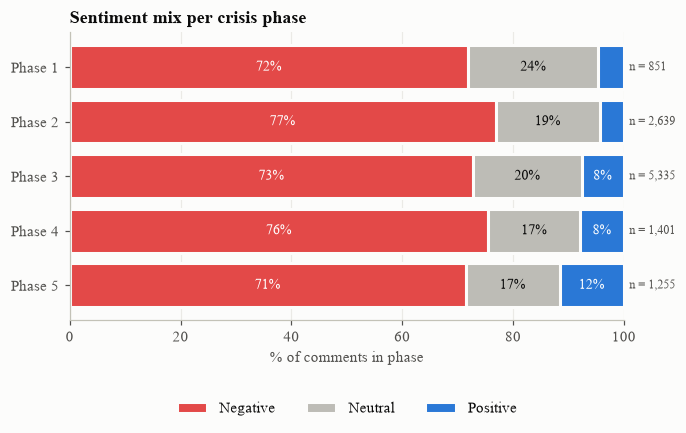

In [7]:
counts = pd.crosstab(df.phase, df.sentiment_label)[["NEGATIVE", "NEUTRAL", "POSITIVE"]]
shares = counts.div(counts.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(6.5, 3.4))
left = np.zeros(len(shares))
for s in shares:
    ax.barh(PHASE_LABELS, shares[s], left=left, color=SENT_COLORS[s], edgecolor="#fcfcfb", linewidth=2, label=s.title())
    for y, (l, w) in enumerate(zip(left, shares[s])):
        if w > 6:
            ax.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=9,
                    color="#ffffff" if s != "NEUTRAL" else "#0b0b0b")
    left += shares[s].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of comments in phase")
ax.grid(axis="y", visible=False)
ax.set_title("Sentiment mix per crisis phase")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.38))
for y, n in enumerate(counts.sum(axis=1)):
    ax.text(101, y, f"n = {n:,}", va="center", fontsize=8, color="#52514e")
save(fig, "rq1_sentiment_mix")
plt.show()

### 1b. Intensity heatmaps: frequency and strength of each sentiment per phase
Left: how often (% of comments). Right: how strongly, measured as the model's mean probability for the label it
assigned (a confidence-based proxy for intensity, 0.33-1.0).

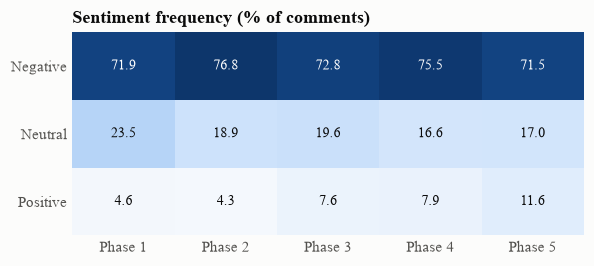

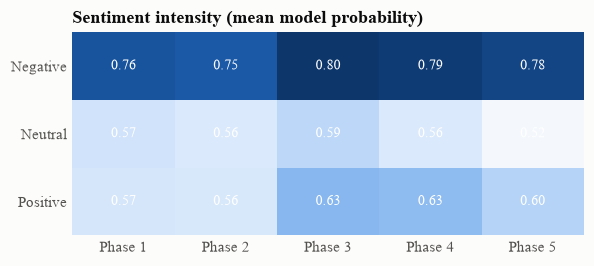

In [8]:
freq = shares.T.rename(index=str.title)
freq.columns = PHASE_LABELS
inten = df.pivot_table(index="sentiment_label", columns="phase", values="sentiment_score", aggfunc="mean", observed=True)
inten = inten.loc[["NEGATIVE", "NEUTRAL", "POSITIVE"]].rename(index=str.title)
inten.columns = PHASE_LABELS
heatmap(freq, "Sentiment frequency (% of comments)", "rq1_heatmap_sentiment_frequency", figsize=(6, 2.4))
heatmap(inten, "Sentiment intensity (mean model probability)", "rq1_heatmap_sentiment_intensity",
        fmt="{:.2f}", figsize=(6, 2.4))

### 1c. Emotion intensity: Sta. Maria's three clusters of Filipino negative social emotion
Sta. Maria (2010) orders Filipino negative social emotions by intensity:

| Cluster | Emotions | Intensity | Focal event |
|---|---|---|---|
| C1 | *suklam, muhi, poot* (loathing, hatred, wrath) | highest | the other violates a moral order |
| C2 | *sama ng loob, galit, tampo* (resentment, anger, sulking) | moderate | the other fails an expectation |
| C3 | *buwisit, asar, ngitngit, yamot, pikon* (irritation, annoyance) | lowest | something hinders the actor's goals |

`Unclassified` is a negative social emotion whose focal event is unclear, so it fits none of the three clusters.
C1 + C2 + C3 + Unclassified add up to "Any negative social emotion".
Shares below are of comments with a successful Sta. Maria coding.

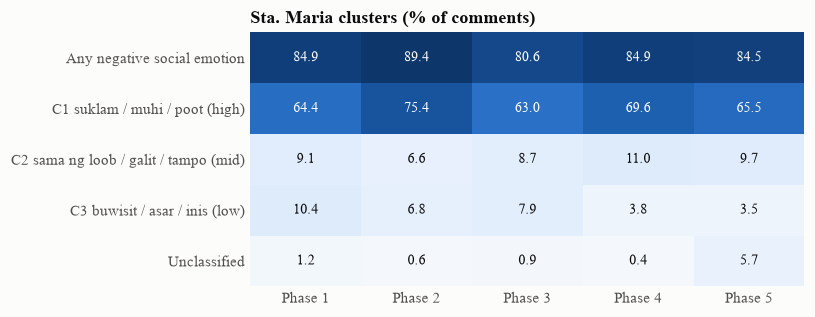

,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Any negative social emotion,9555,83.9,84.9,89.4,80.6,84.9,84.5,-0.5,0.095,5.94e-21,-3.29,0.00186,"enduring, declining"
C1 suklam / muhi / poot (high),7637,67.1,64.4,75.4,63.0,69.6,65.5,1.2,0.106,2.56e-26,-3.34,0.00186,"enduring, declining"
C2 sama ng loob / galit / tampo (mid),983,8.6,9.1,6.6,8.7,11.0,9.7,0.7,0.048,3.23e-05,+3.42,0.00186,"enduring, rising"
C3 buwisit / asar / inis (low),783,6.9,10.4,6.8,7.9,3.8,3.5,-6.9,0.078,8.36e-14,-6.61,1.56e-10,"enduring, declining"
Unclassified,152,1.3,1.2,0.6,0.9,0.4,5.7,4.5,0.135,4.42e-43,+9.32,5.63e-20,phase-specific (2/5 phases)


In [9]:
fe_df = df[df.fe_ok]
CLU = ["NEG_SOCIAL_EMOTION", "CLUSTER_C1", "CLUSTER_C2", "CLUSTER_C3", "CLUSTER_UNCLASSIFIED"]
CLU_NAMES = {"NEG_SOCIAL_EMOTION": "Any negative social emotion",
             "CLUSTER_C1": "C1 suklam / muhi / poot (high)", "CLUSTER_C2": "C2 sama ng loob / galit / tampo (mid)",
             "CLUSTER_C3": "C3 buwisit / asar / inis (low)", "CLUSTER_UNCLASSIFIED": "Unclassified"}
fe_df = fe_df.assign(NEG_SOCIAL_EMOTION=fe_df.NEG_SOCIAL_EMOTION.fillna(0).astype(int))
clu_end = endurance(fe_df, CLU, CLU_NAMES)
clu_end.to_csv(OUT / "rq1_stamaria_clusters_by_phase.csv")
heatmap(wide_share(clu_end), "Sta. Maria clusters (% of comments)", "rq1_heatmap_stamaria_intensity",
        figsize=(6.5, 3))
show(clu_end)

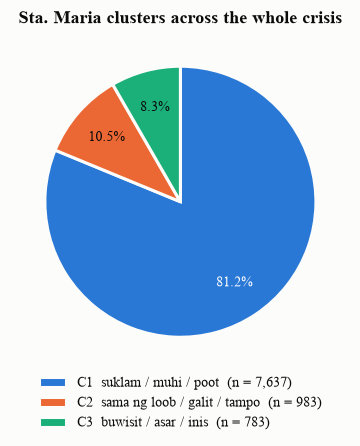

9,403 comments in C1-C3; 152 unclassified not shown


In [10]:
# Whole-crisis distribution of the three clusters (unclassified left out)
C3_ONLY = {"C1 suklam / muhi / poot (high)": "C1  suklam / muhi / poot",
           "C2 sama ng loob / galit / tampo (mid)": "C2  sama ng loob / galit / tampo",
           "C3 buwisit / asar / inis (low)": "C3  buwisit / asar / inis"}
pie_n = clu_end.loc[list(C3_ONLY), "total"].rename(C3_ONLY)
fig, ax = plt.subplots(figsize=(5.2, 4))
wedges, _, autotexts = ax.pie(pie_n, colors=SERIES[:3], startangle=90, counterclock=False,
                              autopct=lambda p: f"{p:.1f}%", pctdistance=0.72,
                              wedgeprops={"edgecolor": "#fcfcfb", "linewidth": 2})
for t, w in zip(autotexts, pie_n):
    t.set_color("#ffffff" if w == pie_n.max() else "#0b0b0b")
    t.set_fontsize(9)
ax.legend(wedges, [f"{k}  (n = {v:,})" for k, v in pie_n.items()], loc="upper center",
          bbox_to_anchor=(0.5, 0.02), ncol=1, fontsize=9)
ax.set_title("Sta. Maria clusters across the whole crisis", loc="center")
save(fig, "rq1_stamaria_pie")
plt.show()
print(f"{int(pie_n.sum()):,} comments in C1-C3; {int(clu_end.loc['Unclassified', 'total'])} unclassified not shown")

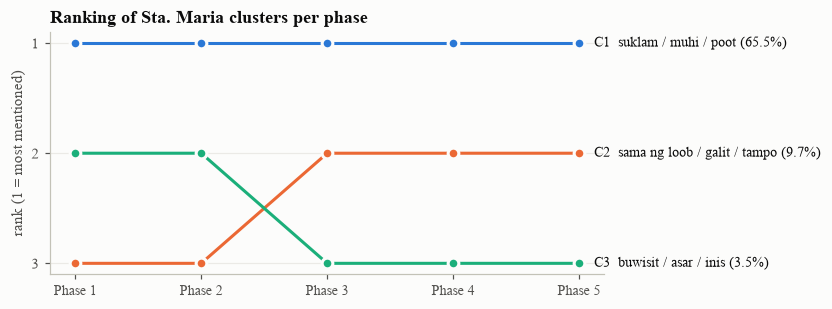

In [11]:
# Ranking of C1 / C2 / C3 in each phase (unclassified left out)
clu3 = clu_end.loc[list(C3_ONLY)].rename(index=C3_ONLY)
bump(clu3, ranks_of(clu3), list(clu3.index), "Ranking of Sta. Maria clusters per phase", "rq1_stamaria_rank")

### 1d. Emotion streams: how each emotion grows or shrinks across the phases
Two stream charts. Each colour is one emotion from the codebook. The **width** of a band at a phase is the % of that
phase's comments carrying the emotion (a comment can carry more than one), so a band that widens means the emotion
became more common. Curves are drawn through the five phase values (monotone interpolation, no overshoot); grey
lines mark the phases.
* **Figure A: the six basic emotions** (anger, sadness, fear, disgust, joy, surprise).
* **Figure B: compassion for the victims vs. sympathy for the offender** (the coach or the school). Condolences are left out.

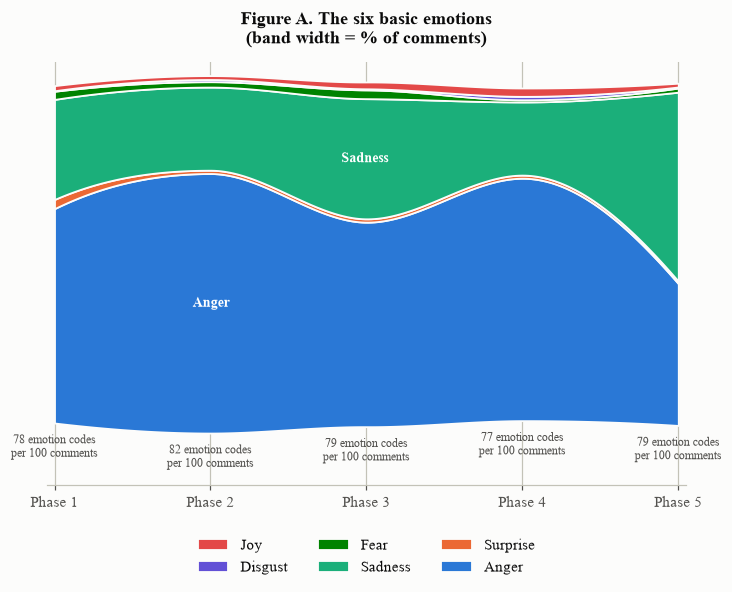

,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5
item,,,,,
Anger,49.4,59.8,47.1,55.8,32.7
Surprise,2.1,0.8,0.8,0.7,0.6
Sadness,23.0,19.1,27.7,16.8,43.5
Fear,1.9,1.3,2.0,0.5,1.0
Disgust,0.1,0.5,0.2,0.8,0.2
Joy,1.2,0.9,1.6,1.9,0.9


In [12]:
STREAM_NAMES = {"ANGER": "Anger", "CONTEMPT": "Contempt", "SADNESS": "Sadness", "CONDOLENCE": "Condolence",
                "COMPASSION_VICTIMS": "Compassion for victims", "FEAR": "Fear", "DISGUST": "Disgust", "JOY": "Joy",
                "SURPRISE": "Surprise", "SYMPATHY_OFFENDER": "Sympathy for offender (coach / school)"}
emo_end = endurance(df, EMOTIONS, STREAM_NAMES)
emo_end.to_csv(OUT / "rq1_emotions_by_phase.csv")
# One colour per emotion, kept the same in both figures
EMO_COLORS = {"ANGER": SERIES[0], "SURPRISE": SERIES[1], "SADNESS": SERIES[2], "SYMPATHY_OFFENDER": SERIES[3],
              "COMPASSION_VICTIMS": SERIES[4], "FEAR": SERIES[5], "DISGUST": SERIES[6], "JOY": SERIES[7]}

def stream(codes, title, fname, label_min=6, note=None, pad=16):
    rates = emo_end.loc[[STREAM_NAMES[e] for e in codes], PHASE_LABELS]
    x = np.arange(len(PHASES))
    xs = np.linspace(0, len(PHASES) - 1, 200)
    smooth = np.vstack([np.clip(PchipInterpolator(x, r)(xs), 0, None) for r in rates.values])
    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.stackplot(xs, smooth, baseline="sym", colors=[EMO_COLORS[e] for e in codes], labels=rates.index,
                 edgecolor="#fcfcfb", linewidth=1.2)
    mids = -smooth.sum(axis=0) / 2 + np.cumsum(smooth, 0) - smooth / 2
    inner = (xs > 0.4) & (xs < len(PHASES) - 1.4)
    for i, name in enumerate(rates.index):
        if rates.iloc[i].max() >= label_min:
            j = np.flatnonzero(inner)[np.argmax(smooth[i, inner])]
            ax.text(xs[j], mids[i, j], name, ha="center", va="center", fontsize=9, color="#ffffff", fontweight="bold")
    for xi in x:
        ax.axvline(xi, color="#c3c2b7", linewidth=0.8, zorder=0)
    tot = rates.sum()
    for xi, ph in zip(x, PHASE_LABELS):
        ax.text(xi, -tot[ph] / 2 - pad * 0.15, note(rates[ph]), ha="center", va="top", fontsize=8, color="#52514e")
    ax.set_xticks(x, PHASE_LABELS)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.set_xlim(-0.05, len(PHASES) - 0.95)
    ax.set_ylim(-tot.max() / 2 - pad * 0.75, tot.max() / 2 + pad * 0.2)
    ax.set_title(title, pad=12, loc="center")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3,
              bbox_transform=offset_copy(ax.transAxes, fig=fig, y=-26, units="points"))
    save(fig, fname)
    plt.show()
    return rates.round(1)

basic = stream(["ANGER", "SURPRISE", "SADNESS", "FEAR", "DISGUST", "JOY"],
               "Figure A. The six basic emotions\n(band width = % of comments)",
               "rq1_emotion_stream_basic", note=lambda r: f"{r.sum():.0f} emotion codes\nper 100 comments")
basic

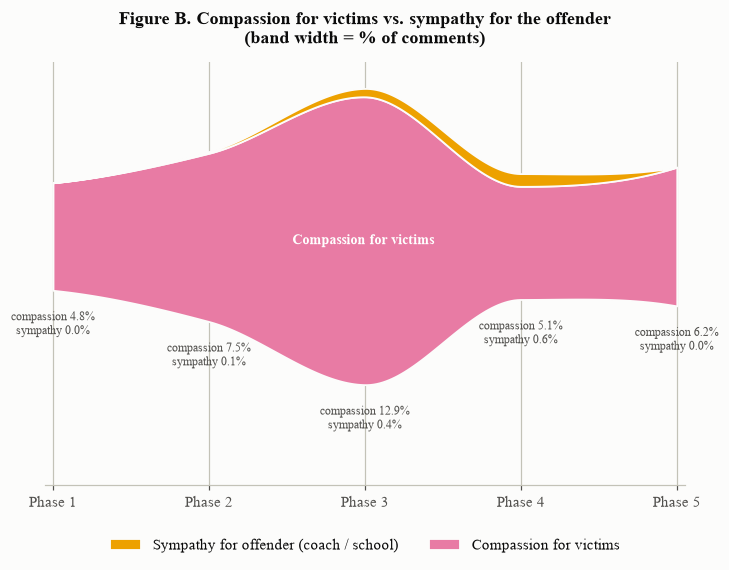

,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5
item,,,,,
Compassion for victims,4.8,7.5,12.9,5.1,6.2
Sympathy for offender (coach / school),0.0,0.1,0.4,0.6,0.0


comments: {'Compassion for victims': 1077, 'Sympathy for offender (coach / school)': 30}


In [13]:
care = stream(["COMPASSION_VICTIMS", "SYMPATHY_OFFENDER"],
              "Figure B. Compassion for victims vs. sympathy for the offender\n(band width = % of comments)",
              "rq1_emotion_stream_compassion", label_min=3, pad=6,
              note=lambda r: f"compassion {r.iloc[0]:.1f}%\nsympathy {r.iloc[1]:.1f}%")
display(care)
print("comments:", {STREAM_NAMES[e]: int(df[e].sum()) for e in ["COMPASSION_VICTIMS", "SYMPATHY_OFFENDER"]})

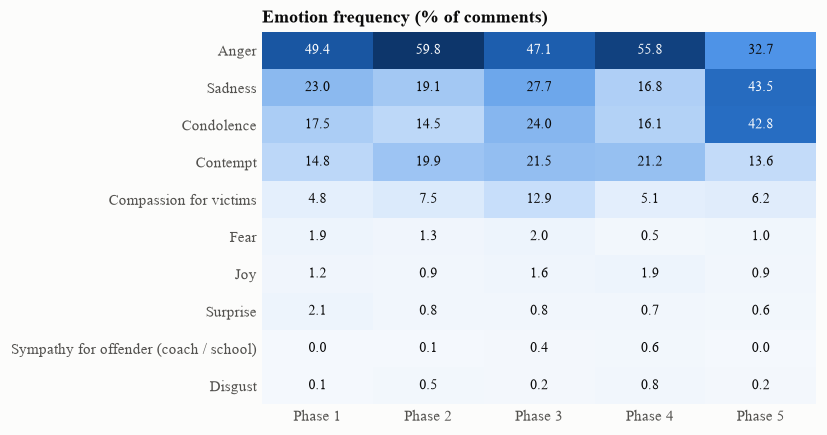

,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Anger,5701,49.7,49.4,59.8,47.1,55.8,32.7,-16.7,0.158,3.38e-60,-10.78,3.34e-26,"enduring, declining"
Sadness,2959,25.8,23.0,19.1,27.7,16.8,43.5,20.5,0.172,4.2e-71,+11.10,1.09e-27,"enduring, rising"
Condolence,2573,22.4,17.5,14.5,24.0,16.1,42.8,25.3,0.197,2.72e-94,+15.40,1.69e-52,"enduring, rising"
Contempt,2267,19.7,14.8,19.9,21.5,21.2,13.6,-1.2,0.070,1.56e-10,-1.17,1,"enduring, stable"
Compassion for victims,1077,9.4,4.8,7.5,12.9,5.1,6.2,1.4,0.116,1.66e-31,-0.42,1,"enduring, stable"
Fear,176,1.5,1.9,1.3,2.0,0.5,1.0,-0.9,0.045,0.000555,-2.00,0.273,phase-specific (3/5 phases)
Joy,156,1.4,1.2,0.9,1.6,1.9,0.9,-0.3,0.032,0.0296,+0.84,1,phase-specific (3/5 phases)
Surprise,96,0.8,2.1,0.8,0.8,0.7,0.6,-1.6,0.040,0.00359,-2.80,0.0362,phase-specific (1/5 phases)
Disgust,41,0.4,0.1,0.5,0.2,0.8,0.2,0.1,0.033,0.0296,+0.53,1,rare (<1% in every phase)


In [14]:
heatmap(wide_share(emo_end).sort_values(PHASE_LABELS[2], ascending=False), "Emotion frequency (% of comments)",
        "rq1_heatmap_emotions", figsize=(6.5, 4.4))
show(emo_end.sort_values("overall_%", ascending=False))

## RQ2 - Topics: what is said about class, values and actions
The topics themselves (top topics per phase, their sentiment, and how they carry over between phases) are in
`05-summary/notebooks/summary.ipynb` sections 4-5 and are not repeated here. This section uses the same BERTopic
output (`topic_id`, `topic_label`, `top_terms`; topic `-1` is the outlier bin and is left out) only to locate class talk.

### 2a. Social class evidence: is class present, and in which topics?
Class themes in the topics. For each topic: the share of its comments that frame the crisis in class terms, how
that compares to the phase average (`lift`), the dominant class theme, and any class words among the topic's own
top terms. Topics with a lift above 1 carry more class talk than their phase as a whole.

In [15]:
tp = df[df.topic_id >= 0]
topics = (tp.groupby(["phase", "topic_id", "topic_label", "top_terms"], observed=True)
            .agg(comments=("comment_id", "size"), class_share=("CLASS_FRAME", "mean"))
            .reset_index())
topics["phase"] = topics.phase.astype(str)
print("comments in a topic (not outliers):", f"{len(tp) / len(df):.0%}")

CLASS_WORDS =r"\b(?:poor|rich|elite|elitist|privileged?|mahirap|mayaman|dukha|taxpayers?|pera|money|scholars?|scholarship|filipinos?|ordinary|masa)\b"
phase_class = df.groupby(df.phase.astype(str)).CLASS_FRAME.mean()
dom = (tp[tp.CLASS_FRAME == 1].groupby(["phase", "topic_id"], observed=True).CLASS_THEME
         .agg(lambda s: s.value_counts().index[0]).rename("dominant_class_theme").map(CLASS_THEMES).reset_index())
dom["phase"] = dom.phase.astype(str)
topics = topics.merge(dom, on=["phase", "topic_id"], how="left")
topics["lift"] = topics.class_share / topics.phase.map(phase_class)
topics["class_terms_in_topic"] = topics.top_terms.str.findall(CLASS_WORDS, flags=re.I).str.join(", ")
topics.to_csv(OUT / "rq2_topics_with_class.csv", index=False)

class_topics = topics[(topics.comments >= 20) & (topics.lift > 1)].sort_values("class_share", ascending=False)
print(f"{len(class_topics)} of {(topics.comments >= 20).sum()} topics (n >= 20) carry more class talk than their phase")
display(class_topics[["phase", "topic_label", "comments", "class_share", "lift", "dominant_class_theme", "top_terms"]].round(2))
print("Topics whose own defining words are class words (any size):")
topics[topics.class_terms_in_topic != ""][["phase", "topic_label", "comments", "class_share", "class_terms_in_topic", "top_terms"]].round(2)

comments in a topic (not outliers): 64%
12 of 31 topics (n >= 20) carry more class talk than their phase


,phase,topic_label,comments,class_share,lift,dominant_class_theme,top_terms
40,05-lingering,UAAP Banning Controversy,20,0.50,3.55,Inequality / injustice & victims as poor,"banned, yan, cla, lng, kulong, wtf, uaap, tab, tsk, baldwin"
22,03-spread,Accident vs. Negligence,77,0.35,1.95,Inequality / injustice & victims as poor,"accident, detector, purely, negligence, lie, cidg, aksidente, lies, preventable, fault"
10,02-confirmation,Ateneo training fatality,298,0.34,1.39,Inequality / injustice & victims as poor,"coach, training, yan, basketball, ateneo, players, player, dagat, team, nyo"
1,01-onset,Ateneo drowning tragedy,162,0.33,1.26,Inequality / injustice & victims as poor,"yan, team, building, alon, coach, ateneo, jan, dyan, nag, mag"
28,04-reckoning,Ateneo training accident,335,0.33,1.58,Inequality / injustice & victims as poor,"coach, training, players, team, ateneo, basketball, safety, yan, accident, two"
12,02-confirmation,Ateneo Negligence Accountability,235,0.31,1.29,Inequality / injustice & victims as poor,"justice, negligence, accident, accountable, ateneo, held, aksidente, school, homicide, purely"
11,02-confirmation,Water rescue negligence,275,0.31,1.28,Inequality / injustice & victims as poor,"rescue, cpr, life, rescuer, training, pool, swimming, water, guard, resort"
14,02-confirmation,Coaching Staff Negligence,45,0.31,1.27,Inequality / injustice & victims as poor,"coaching, coach, ateneo, team, uaap, negligence, staff, players, season, coaches"
32,04-reckoning,Child abuse and murder,20,0.30,1.44,Inequality / injustice & victims as poor,"murder, anu, killed, school, cahiwat, molester, masakit, child, sama, yan"
36,05-lingering,Ateneo accident controversy,314,0.27,1.90,Inequality / injustice & victims as poor,"rene, yan, nya, wala, anak, nyo, coach, ateneo, players, nangyari"


Topics whose own defining words are class words (any size):


,phase,topic_label,comments,class_share,class_terms_in_topic,top_terms
35,04-reckoning,Ateneo Justice Demands,12,0.42,"poor, filipinos, filipino, taxpayers","poor, filipinos, filipino, philippines, taxpayers, ateneo, justice, fake, skilled, native"


In [16]:
lex = df.text.fillna("").str.contains(CLASS_WORDS, flags=re.I, regex=True)
print("Comments using explicit class vocabulary (poor/rich/elite/mahirap/mayaman/pera/scholar ...):",
      int(lex.sum()), f"({lex.mean():.1%})")
print("...of which coded as class-framed by the codebook:", f"{df.loc[lex, 'CLASS_FRAME'].mean():.0%}",
      "| class-framed rate among the rest:", f"{df.loc[~lex, 'CLASS_FRAME'].mean():.0%}")

Comments using explicit class vocabulary (poor/rich/elite/mahirap/mayaman/pera/scholar ...): 445 (3.9%)
...of which coded as class-framed by the codebook: 69% | class-framed rate among the rest: 18%


### 2b. How much class talk in each phase, and is it there in every phase?
(The analysis the advisers liked from `02-statistical-analysis`, rerun on the final v1.8 coding.)

In [17]:
g = df.groupby("phase", observed=True).CLASS_FRAME.agg(["sum", "count"])
g["share"] = g["sum"] / g["count"]
g["ci_lo"], g["ci_hi"] = wilson(g["sum"], g["count"])
rq1_table = pd.DataFrame({
    "Crisis Phase": PHASE_LABELS, "Total Comments": g["count"].values, "Class Talk Volume": g["sum"].values,
    "Class Talk Share": (g.share * 100).round(1).astype(str).values + "%",
    "95% CI": ["[" + f"{l:.3f}, {h:.3f}" + "]" for l, h in zip(g.ci_lo, g.ci_hi)]})
rq1_table.to_csv(OUT / "rq2_class_volume_table.csv", index=False)
display(rq1_table)

tab = pd.crosstab(df.phase, df.CLASS_FRAME)
chi2, p, dof, exp = stats.chi2_contingency(tab)
print(f"chi2({dof}) = {chi2:.2f}, p = {p:.3g}, Cramer's V = {np.sqrt(chi2 / tab.values.sum()):.3f}")
z, pz = ca_trend(g["sum"], g["count"], np.arange(len(g)))
print(f"Cochran-Armitage trend: z = {z:.2f}, p = {pz:.3g}")
rp, cp = tab.sum(axis=1).values[:, None] / tab.values.sum(), tab.sum(axis=0).values / tab.values.sum()
adj = (tab.values - exp) / np.sqrt(exp * (1 - rp) * (1 - cp))
print("adjusted residuals (|r| > 1.96 = phase differs from expectation):")
print(pd.DataFrame(adj, index=PHASE_LABELS, columns=["no class frame", "class frame"]).round(2))

,Crisis Phase,Total Comments,Class Talk Volume,Class Talk Share,95% CI
0,Phase 1,851,225,26.4%,"[0.236, 0.295]"
1,Phase 2,2639,645,24.4%,"[0.228, 0.261]"
2,Phase 3,5335,961,18.0%,"[0.170, 0.191]"
3,Phase 4,1401,292,20.8%,"[0.188, 0.230]"
4,Phase 5,1255,177,14.1%,"[0.123, 0.161]"


chi2(4) = 95.51, p = 8.86e-20, Cramer's V = 0.091
Cochran-Armitage trend: z = -8.13, p = 4.45e-16
adjusted residuals (|r| > 1.96 = phase differs from expectation):
         no class frame  class frame
Phase 1           -4.85         4.85
Phase 2           -6.45         6.45
Phase 3            5.04        -5.04
Phase 4           -0.81         0.81
Phase 5            5.56        -5.56


### 2c. Which class themes: inequality / injustice & victims as poor, elitism, N/A
The codebook's `CLASS_DIRECTION` values are grouped into three themes:
`INEQUALITY_JUSTICE` + `VICTIMS_POOR` = **Inequality / injustice & victims as poor**;
`INSTITUTION_ELITE` = **Elitism**; `OTHER` + class talk with no direction coded = **N/A**.

In [18]:
cls_end = endurance(df, CLS, {f"CLS_{k}": v for k, v in CLASS_THEMES.items()})
cls_end.to_csv(OUT / "rq2_class_themes_by_phase.csv")

cf = df[df.CLASS_FRAME == 1]
mix = pd.crosstab(cf.phase, cf.CLASS_THEME.map(CLASS_THEMES))[list(CLASS_THEMES.values())]
print("Within class-framed comments (% per phase):")
display((mix.div(mix.sum(axis=1), axis=0) * 100).round(1).set_axis(PHASE_LABELS))
show(cls_end)

Within class-framed comments (% per phase):


CLASS_THEME,Inequality / injustice & victims as poor,Elitism (institution / elite),N/A (other or no direction coded)
Phase 1,87.6,1.8,10.7
Phase 2,90.4,3.6,6.0
Phase 3,89.1,1.2,9.7
Phase 4,87.7,3.1,9.2
Phase 5,95.5,0.0,4.5


,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Inequality / injustice & victims as poor,2061,18.0,23.1,22.1,16.0,18.3,13.5,-9.7,0.082,2.58e-15,-7.14,2.76e-12,"enduring, declining"
Elitism (institution / elite),48,0.4,0.5,0.9,0.2,0.6,0.0,-0.5,0.047,0.000109,-2.81,0.01,rare (<1% in every phase)
N/A (other or no direction coded),191,1.7,2.8,1.5,1.7,1.9,0.6,-2.2,0.038,0.00253,-2.58,0.01,phase-specific (4/5 phases)


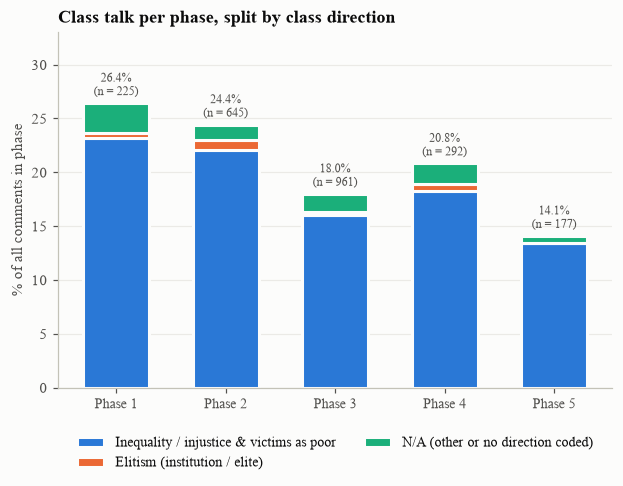

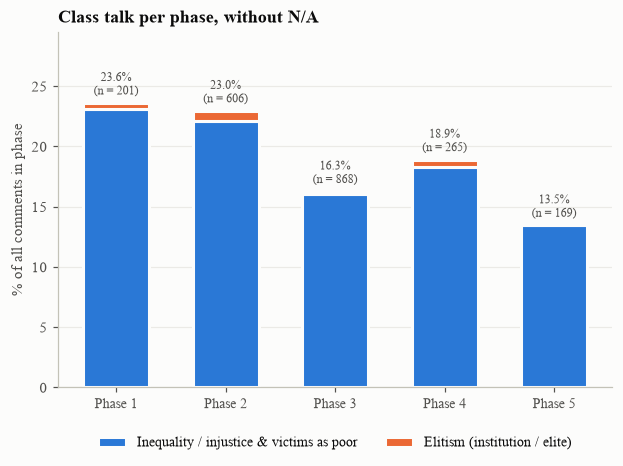

In [19]:
def class_bars(table, colors, title, fname):
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    x = np.arange(len(PHASES))
    bottom = np.zeros(len(PHASES))
    for name, color in zip(table.index, colors):
        v = table.loc[name, PHASE_LABELS].values
        ax.bar(x, v, bottom=bottom, width=0.6, color=color, edgecolor="#fcfcfb", linewidth=2, label=name)
        bottom += v
    # n = comments in the stacked groups shown (bar height x comments in phase)
    for xi, b, n in zip(x, bottom, np.rint(bottom * g["count"].values / 100).astype(int)):
        ax.text(xi, b + 0.4, f"{b:.1f}%\n(n = {n})", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_xticks(x, PHASE_LABELS)
    ax.set_ylabel("% of all comments in phase")
    ax.set_ylim(0, bottom.max() * 1.25)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=9)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2, fontsize=9,
              bbox_transform=offset_copy(ax.transAxes, fig=fig, y=-24, units="points"))
    save(fig, fname)
    plt.show()

# Grouped: inequality / injustice and victims as poor together
class_bars(cls_end.loc[list(CLASS_THEMES.values())], [SERIES[0], SERIES[1], SERIES[2]],
           "Class talk per phase, split by class direction", "rq2_class_themes")
# Option without N/A (advisers asked for both versions)
class_bars(cls_end.loc[[CLASS_THEMES["INEQUALITY_JUSTICE_VICTIMS"], CLASS_THEMES["ELITISM"]]], [SERIES[0], SERIES[1]],
           "Class talk per phase, without N/A", "rq2_class_themes_no_na")

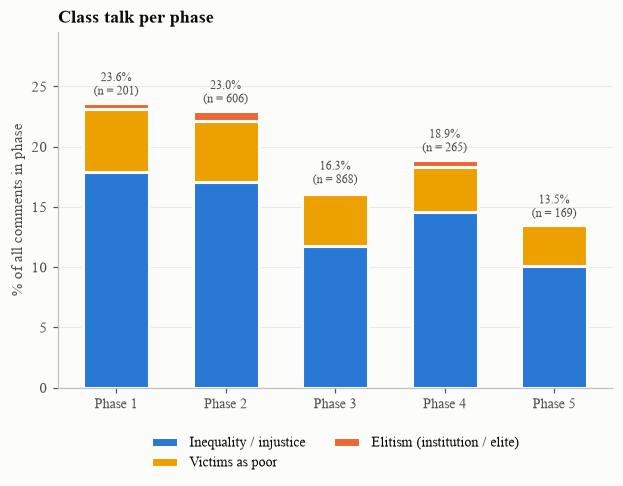

,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Inequality / injustice,1558,13.6,17.9,17.1,11.7,14.6,10.1,-7.7,0.078,8.22e-14,-6.22,1.99e-09,"enduring, declining"
Victims as poor,503,4.4,5.3,5.0,4.3,3.7,3.3,-1.9,0.028,0.0577,-2.98,0.00851,"enduring, declining"
Elitism (institution / elite),48,0.4,0.5,0.9,0.2,0.6,0.0,-0.5,0.047,0.000163,-2.81,0.01,rare (<1% in every phase)
N/A (other or no direction coded),191,1.7,2.8,1.5,1.7,1.9,0.6,-2.2,0.038,0.00506,-2.58,0.01,phase-specific (4/5 phases)


In [20]:
# Same chart with inequality / injustice and victims as poor shown separately
SPLIT = {"INEQUALITY_JUSTICE": "Inequality / injustice", "VICTIMS_POOR": "Victims as poor",
         "ELITISM": CLASS_THEMES["ELITISM"], "NA": CLASS_THEMES["NA"]}
for k in ["INEQUALITY_JUSTICE", "VICTIMS_POOR"]:
    df[f"CLS_{k}"] = df.CLASS_DIRECTION.eq(k).astype(int)
cls_split = endurance(df, [f"CLS_{k}" for k in SPLIT], {f"CLS_{k}": v for k, v in SPLIT.items()})
cls_split.to_csv(OUT / "rq2_class_themes_split_by_phase.csv")
# N/A left out: only inequality / injustice, victims as poor and elitism
class_bars(cls_split.loc[["Inequality / injustice", "Victims as poor", "Elitism (institution / elite)"]],
           [SERIES[0], SERIES[3], SERIES[1]], "Class talk per phase", "rq2_class_themes_split")
show(cls_split)

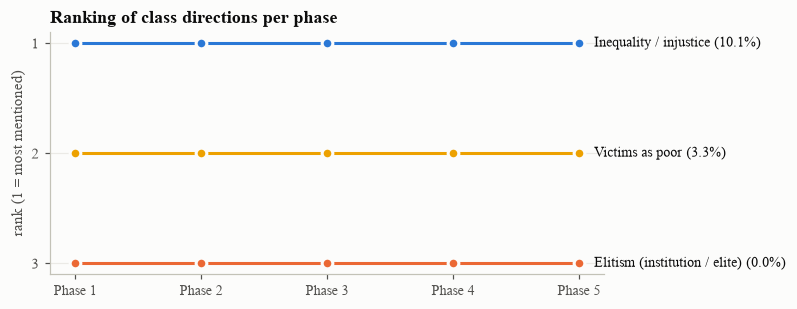

In [21]:
# Ranking of the class directions in each phase (N/A left out)
cls_rank = cls_split.loc[["Inequality / injustice", "Victims as poor", "Elitism (institution / elite)"]]
bump(cls_rank, ranks_of(cls_rank), list(cls_rank.index), "Ranking of class directions per phase",
     "rq2_class_rank", colors=[SERIES[0], SERIES[3], SERIES[1]])

### 2d. Values: which values are invoked, and how do they rank in each phase?
Rank 1 = the most frequent value in that phase. A value that keeps a similar rank across all five phases is an
enduring value.

In [22]:
VAL_NAMES = {c: c[2:].replace("_", " ").title() for c in VALUES}
VAL_NAMES.update({"V_EDUCATION_MOBILITY": "Education / mobility", "V_CHILD_POTENTIAL": "Child potential",
                  "V_DUTY_OF_CARE": "Duty of care", "V_SANCTITY_OF_LIFE": "Sanctity of life",
                  "V_PARENT_SACRIFICE": "Parent sacrifice"})
val_end = endurance(df, VALUES, VAL_NAMES).sort_values("overall_%", ascending=False)
val_end.to_csv(OUT / "rq2_values_by_phase.csv")

ranks = val_end[PHASE_LABELS].rank(ascending=False, method="min").astype(int)
ranks["overall rank"] = val_end["overall_%"].rank(ascending=False, method="min").astype(int)
ranks["rank range"] = ranks[PHASE_LABELS].max(axis=1) - ranks[PHASE_LABELS].min(axis=1)
ranks.to_csv(OUT / "rq2_values_rank.csv")
print("Rank of each value per phase:")
display(ranks)
show(val_end)

Rank of each value per phase:


,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,overall rank,rank range
item,,,,,,,
Justice,1,1,1,1,1,1,0
Sanctity of life,2,2,2,2,5,2,3
Family,6,5,4,3,2,3,4
Child potential,4,4,2,4,3,4,2
Solidarity,7,7,5,5,4,5,3
Duty of care,3,3,6,6,9,6,6
Education / mobility,5,6,7,7,8,7,3
Faith,8,9,8,8,7,8,2
Parent sacrifice,9,8,9,9,6,9,3


,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Justice,2403,20.9,14.7,17.5,18.6,23.8,39.1,24.4,0.165,9.02e-66,+15.29,8.86e-52,"enduring, rising"
Sanctity of life,1571,13.7,12.6,12.5,15.8,14.7,6.6,-6.0,0.083,1.59e-15,-2.98,0.0116,"enduring, declining"
Family,1403,12.2,5.9,6.9,13.3,12.3,22.8,16.9,0.144,1.62e-49,+14.11,3.03e-44,"enduring, rising"
Child potential,1357,11.8,9.5,7.2,15.8,8.8,9.5,-0.0,0.118,1.45e-32,+1.66,0.29,"enduring, stable"
Solidarity,922,8.0,3.6,2.5,11.7,7.8,7.4,3.8,0.140,8.43e-47,+6.61,2.63e-10,"enduring, rising"
Duty of care,842,7.3,10.7,8.8,7.3,7.5,1.7,-9.0,0.085,3.86e-16,-8.13,3.43e-15,"enduring, declining"
Education / mobility,488,4.3,6.1,4.1,3.9,5.1,3.6,-2.5,0.033,0.0256,-1.45,0.292,"enduring, stable"
Faith,266,2.3,1.3,0.8,2.7,2.9,3.9,2.6,0.066,1.14e-09,+6.25,2.41e-09,phase-specific (4/5 phases)
Parent sacrifice,238,2.1,0.8,1.6,2.2,1.5,4.1,3.3,0.058,1.89e-07,+4.96,3.45e-06,phase-specific (4/5 phases)


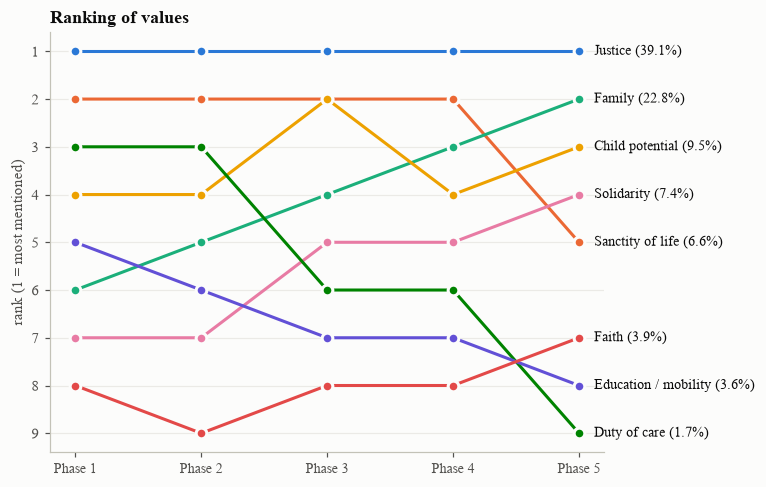

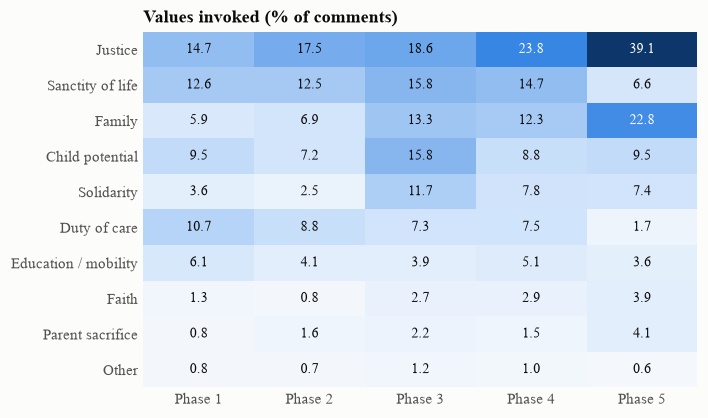

In [23]:
top_vals = [v for v in val_end.index if v != "Other"][:8]
bump(val_end, ranks, top_vals, "Ranking of values", "rq2_values_rank")
heatmap(val_end[PHASE_LABELS], "Values invoked (% of comments)", "rq2_heatmap_values", figsize=(6.5, 4.2))

### 2e. Actions demanded

,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5
item,,,,,
Accountability,2,2,1,2,1
Punitive,1,1,2,1,2
Restitution,3,3,5,3,4
Information,5,4,3,5,4
Support,8,6,4,7,3
Reform,4,5,6,6,7
Boycott,6,7,7,4,6
Retaliation,6,8,8,8,7


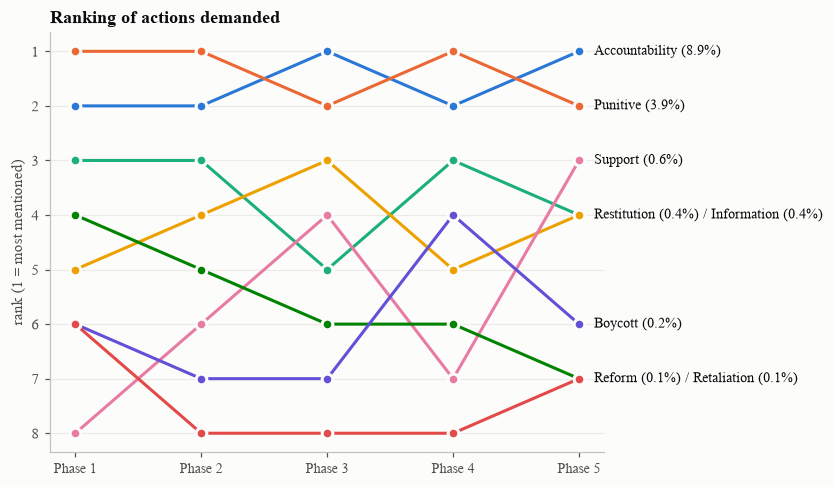

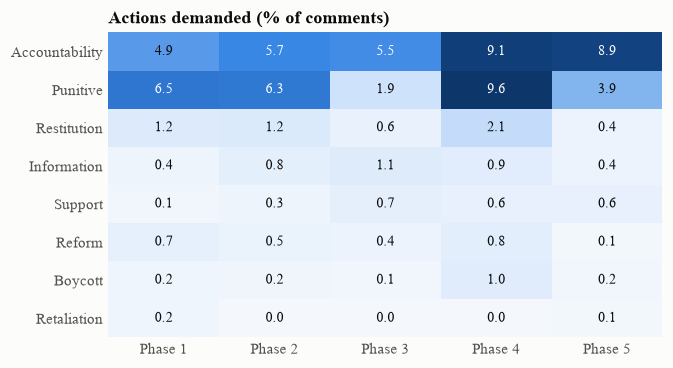

,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Accountability,727,6.3,4.9,5.7,5.5,9.1,8.9,4.0,0.061,6.23e-08,+5.31,8.87e-07,"enduring, rising"
Punitive,504,4.4,6.5,6.3,1.9,9.6,3.9,-2.6,0.133,4.03e-42,-1.14,1,"enduring, stable"
Restitution,108,0.9,1.2,1.2,0.6,2.1,0.4,-0.8,0.056,2.07e-06,-0.74,1,phase-specific (3/5 phases)
Information,98,0.9,0.4,0.8,1.1,0.9,0.4,0.0,0.028,0.109,+0.07,1,phase-specific (1/5 phases)
Support,64,0.6,0.1,0.3,0.7,0.6,0.6,0.5,0.030,0.109,+2.21,0.187,rare (<1% in every phase)
Reform,50,0.4,0.7,0.5,0.4,0.8,0.1,-0.6,0.029,0.109,-1.24,1,rare (<1% in every phase)
Boycott,31,0.3,0.2,0.2,0.1,1.0,0.2,-0.1,0.053,1.07e-05,+1.76,0.476,rare (<1% in every phase)
Retaliation,4,0.0,0.2,0.0,0.0,0.0,0.1,-0.2,0.033,0.0605,-0.89,1,rare (<1% in every phase)


In [24]:
ACT_NAMES = {c: c[2:].title() for c in ACTIONS}
act_end = endurance(df, ACTIONS, ACT_NAMES).sort_values("overall_%", ascending=False)
act_end.to_csv(OUT / "rq2_actions_by_phase.csv")
act_ranks = act_end[PHASE_LABELS].rank(ascending=False, method="min").astype(int)
act_ranks.to_csv(OUT / "rq2_actions_rank.csv")
display(act_ranks)
bump(act_end, act_ranks, list(act_end.index), "Ranking of actions demanded", "rq2_actions_rank")
heatmap(act_end[PHASE_LABELS], "Actions demanded (% of comments)", "rq2_heatmap_actions", figsize=(6.5, 3.6))
show(act_end)

### 2f. What is said alongside class?
Rate of each emotion, value and action in class-framed comments versus all other comments. Shown as a frequency
comparison only (the regression models of the second half of `02-statistical-analysis` are not repeated here).
One chart each for emotions, values and actions. Items are **ranked by how often they appear in class-framed
comments** (#1 = most common); the blue bar is the rate in class-framed comments and the grey bar the rate in all other comments. `*` = the difference is significant
(Fisher's exact test, Holm-adjusted p < .05).

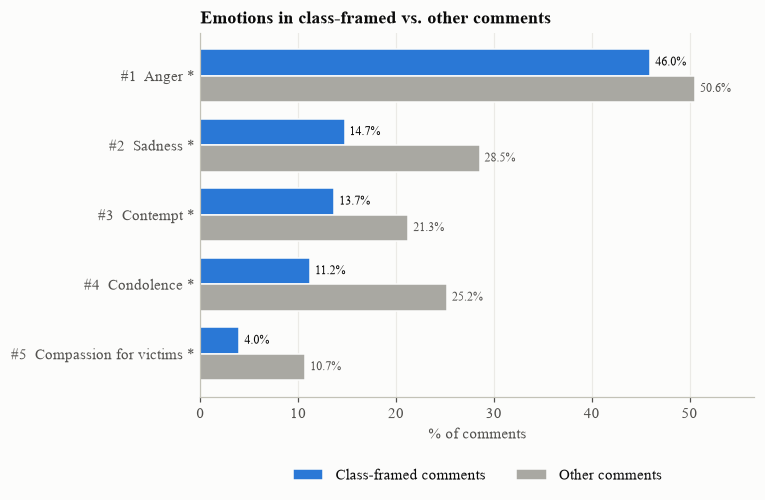

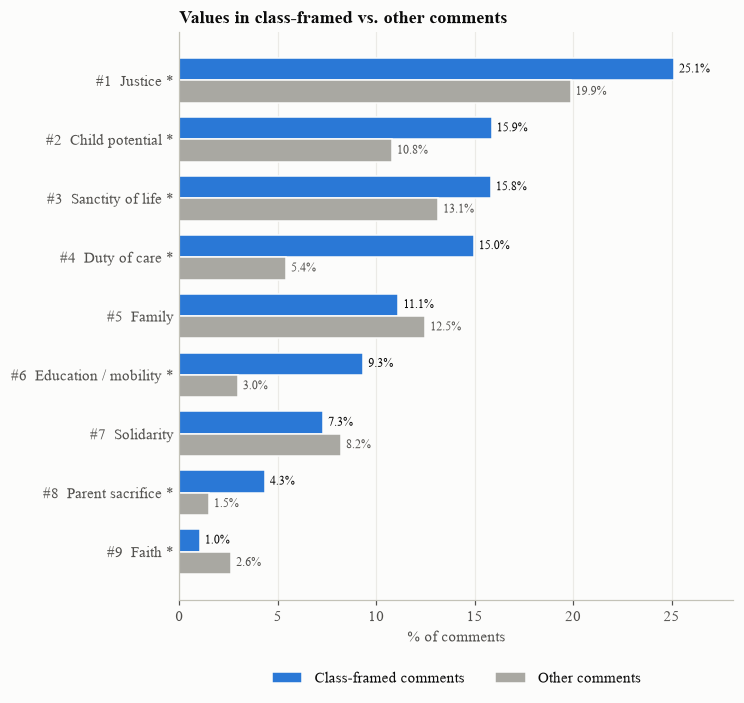

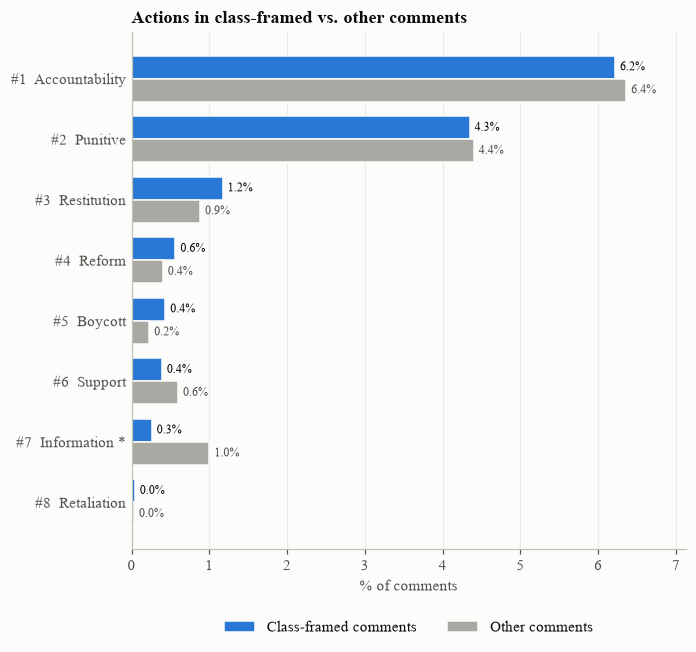

In [25]:
cols = {**{e: STREAM_NAMES.get(e, e) for e in ["ANGER", "CONTEMPT", "SADNESS", "CONDOLENCE", "COMPASSION_VICTIMS"]},
        **{v: VAL_NAMES[v] for v in VALUES}, **{a: ACT_NAMES[a] for a in ACTIONS}}
rows = []
for c, name in cols.items():
    a, b = df.loc[df.CLASS_FRAME == 1, c], df.loc[df.CLASS_FRAME == 0, c]
    _, p = stats.fisher_exact([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])
    rows.append({"item": name, "group": "emotion" if c in EMOTIONS else "value" if c in VALUES else "action",
                 "class-framed %": 100 * a.mean(), "other %": 100 * b.mean(), "p": p})
with_class = pd.DataFrame(rows).set_index("item")
with_class["difference_pp"] = with_class["class-framed %"] - with_class["other %"]
with_class["p_holm"] = holm(with_class.p)
with_class = with_class.drop(index="Other", errors="ignore")
with_class["rank_in_class"] = with_class.groupby("group")["class-framed %"].rank(ascending=False, method="min").astype(int)
with_class.to_csv(OUT / "rq2_with_class.csv")

def class_compare(group, title, fname):
    t = with_class[with_class.group == group].sort_values("class-framed %", ascending=False)
    y = np.arange(len(t))
    h = 0.38
    fig, ax = plt.subplots(figsize=(6.5, 0.6 * len(t) + 1.3))
    ax.barh(y - h / 2, t["class-framed %"], height=h, color=SERIES[0], edgecolor="#fcfcfb", linewidth=1,
            label="Class-framed comments")
    ax.barh(y + h / 2, t["other %"], height=h, color="#a9a8a2", edgecolor="#fcfcfb", linewidth=1,
            label="Other comments")
    xmax = t[["class-framed %", "other %"]].values.max()
    for yi, (c, o) in enumerate(zip(t["class-framed %"], t["other %"])):
        ax.text(c + xmax * 0.01, yi - h / 2, f"{c:.1f}%", va="center", fontsize=8, color="#0b0b0b")
        ax.text(o + xmax * 0.01, yi + h / 2, f"{o:.1f}%", va="center", fontsize=8, color="#52514e")
    labels = [f"#{r}  {name}{' *' if p < ALPHA else ''}" for name, r, p in zip(t.index, t.rank_in_class, t.p_holm)]
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlim(0, xmax * 1.12)
    ax.set_xlabel("% of comments")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2,
              bbox_transform=offset_copy(ax.transAxes, fig=fig, y=-38, units="points"))
    save(fig, fname)
    plt.show()

class_compare("emotion", "Emotions in class-framed vs. other comments", "rq2_with_class_emotions")
class_compare("value", "Values in class-framed vs. other comments", "rq2_with_class_values")
class_compare("action", "Actions in class-framed vs. other comments", "rq2_with_class_actions")

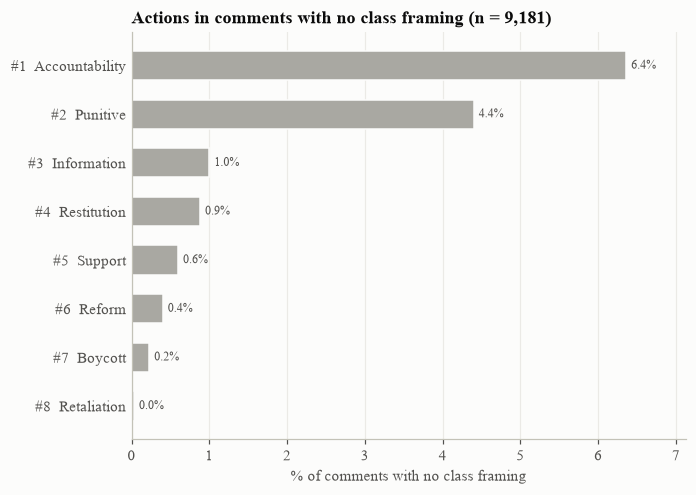

In [26]:
# Actions in comments with NO class framing only, ranked within that group
t = with_class[with_class.group == "action"].sort_values("other %", ascending=False)
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(t) + 1.2))
ax.barh(y, t["other %"], height=0.6, color="#a9a8a2", edgecolor="#fcfcfb", linewidth=1)
for yi, v in enumerate(t["other %"]):
    ax.text(v + t["other %"].max() * 0.01, yi, f"{v:.1f}%", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, [f"#{i + 1}  {name}" for i, name in enumerate(t.index)])
ax.invert_yaxis()
ax.set_xlim(0, t["other %"].max() * 1.12)
ax.set_xlabel("% of comments with no class framing")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Actions in comments with no class framing (n = {int((df.CLASS_FRAME == 0).sum()):,})")
save(fig, "rq2_actions_no_class")
plt.show()

In [27]:
def quotes(d, by, n=2, seed=1):
    return (d.sample(frac=1, random_state=seed).groupby(by, observed=True).head(n)
             .sort_values(by)[[*([by] if isinstance(by, str) else by), "phase", "text"]])

print("Example class-framed comments per class theme:")
quotes(cf.assign(theme=cf.CLASS_THEME.map(CLASS_THEMES)), "theme", n=3)

Example class-framed comments per class theme:


,theme,phase,text
1346,Elitism (institution / elite),02-confirmation,gross negligence of ateneo top administration.
9705,Elitism (institution / elite),04-reckoning,these elite animals obviously trying to cover a nearly perfect crime.
1156,Elitism (institution / elite),02-confirmation,dapat yung ateneo ang sumasagot sa mga tanong ng press.
8643,Inequality / injustice & victims as poor,03-spread,for sure alam nila maraming d marunong lumangoy. so bakit sa dagat sila na delikado na malunod ang mga bata. dapat ma convict ang coach or sino man ang may pasimuno ng team building na yon!
10416,Inequality / injustice & victims as poor,05-lingering,gigil na gigil ako sa mga o pagmumukha lahat ng mga kasamahan ni rene players sa admu. anak mga mayaman basura naman ang pang uugali. kaya dapat ipagkakalat yong video kung paano nila bina batok batukan si rene para ...
5550,Inequality / injustice & victims as poor,03-spread,luckily some of you survived.. well atleast man sana isa sa inyo nagmalasakit na i push through ung cpr thats the only chance they could have survived you all just let those unprofessional people get the body.. if yo...
2623,N/A (other or no direction coded),02-confirmation,pagkalunod ng tao imposibleng lumutang ang katawan
6372,N/A (other or no direction coded),03-spread,"it's good na nag-open up itong dalawang bata. speaking about a traumatic event is a form of debriefing / processing the experience. basta boys, remember na tapos na ung incident. you are safe now. wala kayong kasalan..."
8330,N/A (other or no direction coded),03-spread,user_d6e8bcc0 how is it problematic? kasi it's from the faculty? can't comprehend that people can actually go against someone above them in the same organization?


## RQ3 - Time: which themes endure across the five phases?
One table across every family. **Enduring** = present (at least 1% of comments) in all five phases.
Among enduring themes, a significant Cochran-Armitage trend (Holm-adjusted within its family) marks it as rising or
declining; otherwise stable. `change_pp` is the percentage-point difference between Phase 5 and Phase 1.

In [28]:
families = {"Sentiment": sent_end, "Emotion": emo_end, "Sta. Maria intensity": clu_end,
            "Class theme": pd.concat([endurance(df, ["CLASS_FRAME"], {"CLASS_FRAME": "Any class talk"}), cls_end]),
            "Value": val_end, "Action": act_end}
summary = pd.concat(families, names=["family", "item"])
summary.to_csv(OUT / "rq3_endurance_summary.csv")
print(summary.groupby("family", sort=False).verdict.value_counts().unstack(fill_value=0))
show(summary)

verdict               enduring, stable  enduring, declining  enduring, rising  rare (<1% in every phase)  phase-specific (3/5 phases)  phase-specific (1/5 phases)  phase-specific (2/5 phases)  \
family                                                                                                                                                                                            
Sentiment                            1                    1                 1                          0                            0                            0                            0   
Emotion                              2                    1                 2                          2                            2                            1                            0   
Sta. Maria intensity                 0                    3                 1                          0                            0                            0                            1   
Class theme              

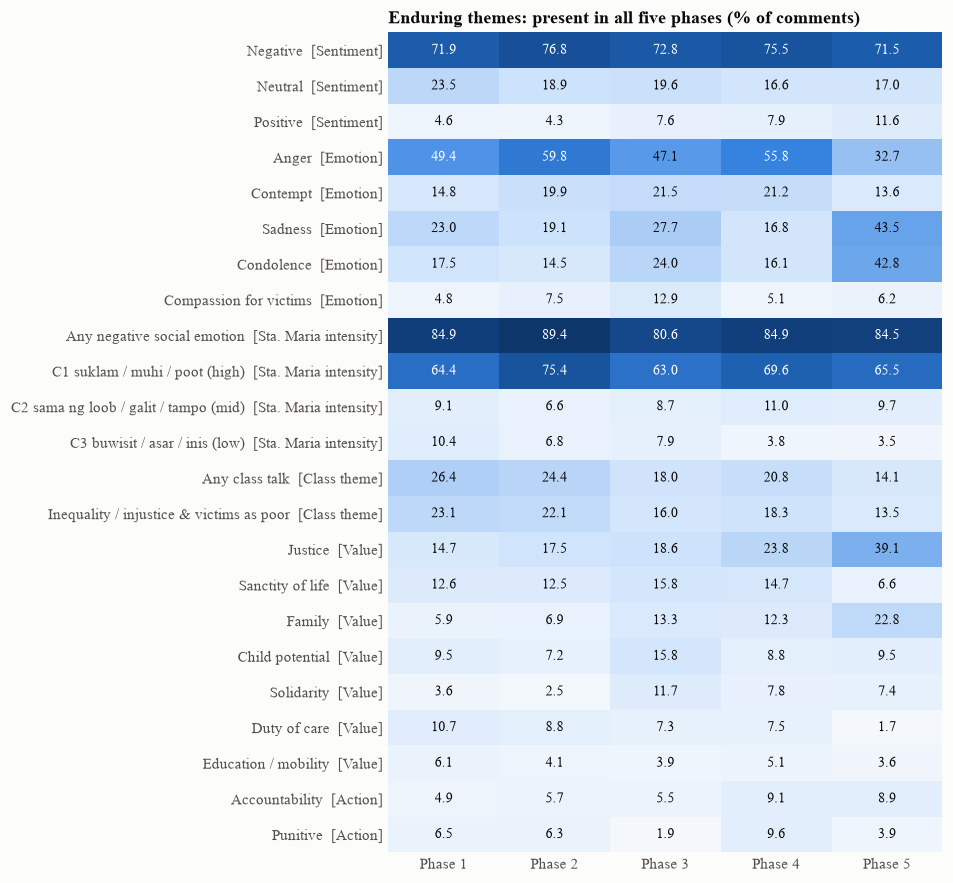

In [29]:
enduring = summary[summary.verdict.str.startswith("enduring")]
idx = enduring.index.map(lambda t: f"{t[1]}  [{t[0]}]")
heatmap(enduring[PHASE_LABELS].set_axis(idx), "Enduring themes: present in all five phases (% of comments)",
        "rq3_heatmap_enduring", figsize=(6.5, 0.36 * len(enduring) + 1.4))

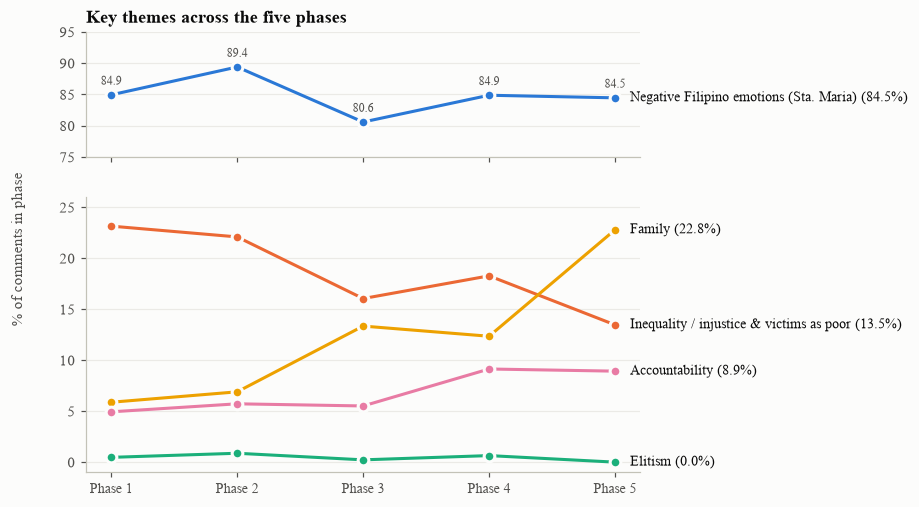

,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5
Negative Filipino emotions (Sta. Maria),84.9,89.4,80.6,84.9,84.5
Inequality / injustice & victims as poor,23.1,22.1,16.0,18.3,13.5
Elitism,0.5,0.9,0.2,0.6,0.0
Family,5.9,6.9,13.3,12.3,22.8
Accountability,4.9,5.7,5.5,9.1,8.9


In [30]:
# Key themes across the phases, one colour each, all comments together (class-framed and other)
key = pd.DataFrame({
    "Negative Filipino emotions (Sta. Maria)": clu_end.loc["Any negative social emotion", PHASE_LABELS],
    "Inequality / injustice & victims as poor": cls_end.loc[CLASS_THEMES["INEQUALITY_JUSTICE_VICTIMS"], PHASE_LABELS],
    "Elitism": cls_end.loc[CLASS_THEMES["ELITISM"], PHASE_LABELS],
    "Family": val_end.loc["Family", PHASE_LABELS],
    "Accountability": act_end.loc["Accountability", PHASE_LABELS],
}).T.astype(float)
key.to_csv(OUT / "rq3_key_themes_by_phase.csv")
# Two panels on the same % scale per panel: negative emotions sit near 85%, the rest under 25%
fig, (top, bot) = plt.subplots(2, 1, figsize=(6.5, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 2.2]})
x = np.arange(len(PHASES))
for i, (name, r) in enumerate(key.iterrows()):
    ax = top if i == 0 else bot
    ax.plot(x, r.values, color=SERIES[i], linewidth=2, marker="o", markersize=7, markeredgecolor="#fcfcfb",
            markeredgewidth=2)
    if i == 0:
        for xi, v in zip(x, r.values):
            ax.text(xi, v + 1.2, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.text(x[-1] + 0.12, r.values[-1], f"{name} ({r.values[-1]:.1f}%)", va="center", fontsize=9)
top.set_ylim(75, 95)
bot.set_ylim(-1, 26)
for ax in (top, bot):
    ax.grid(axis="x", visible=False)
    ax.set_xlim(-0.2, len(PHASES) - 0.8)
bot.set_xticks(x, PHASE_LABELS, fontsize=9)
fig.supylabel("% of comments in phase", fontsize=10, color="#52514e")
top.set_title("Key themes across the five phases")
save(fig, "rq3_key_themes_by_phase")
plt.show()
key.round(1)

## Filipino lens - emotions and values in Filipino language and culture
### F1. Filipino emotion words used literally
The runner searched every negative-emotion comment for Sta. Maria's Filipino emotion terms in any affixed form
(*nagagalit, nakakainis, ...*). Counts are small because most anger is expressed without naming the emotion,
but they show which Filipino emotion vocabulary people reach for.

In [31]:
W_NAMES = {c: c[2:].replace("_", " ").lower() for c in FIL_WORDS}
words = df.groupby("phase", observed=True)[FIL_WORDS].sum().T.set_axis(PHASE_LABELS, axis=1)
words.insert(0, "all phases", words.sum(axis=1))
words.rename(index=W_NAMES).sort_values("all phases", ascending=False)

,all phases,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5
galit,82,1,10,51,10,10
inis,56,6,18,24,6,2
inggit,51,1,8,32,3,7
selos,7,1,0,5,0,1
pikon,3,0,0,2,1,0
sama ng loob,2,0,0,1,1,0
poot,2,0,1,1,0,0
asar,1,0,1,0,0,0
ngitngit,1,0,0,0,0,1
suklam,1,0,1,0,0,0


### F2. Opening up anger and disgust: how Filipinos say it
The codebook's `DISGUST` is rare (most disgust in Filipino is voiced as contempt or insult), so we open up anger and
disgust with a transparent lexicon of Filipino and Taglish expressions, plus culture-specific grief and value words.
Each row is a regular expression on the raw comment; rates are per 1,000 comments so phases of different sizes compare.

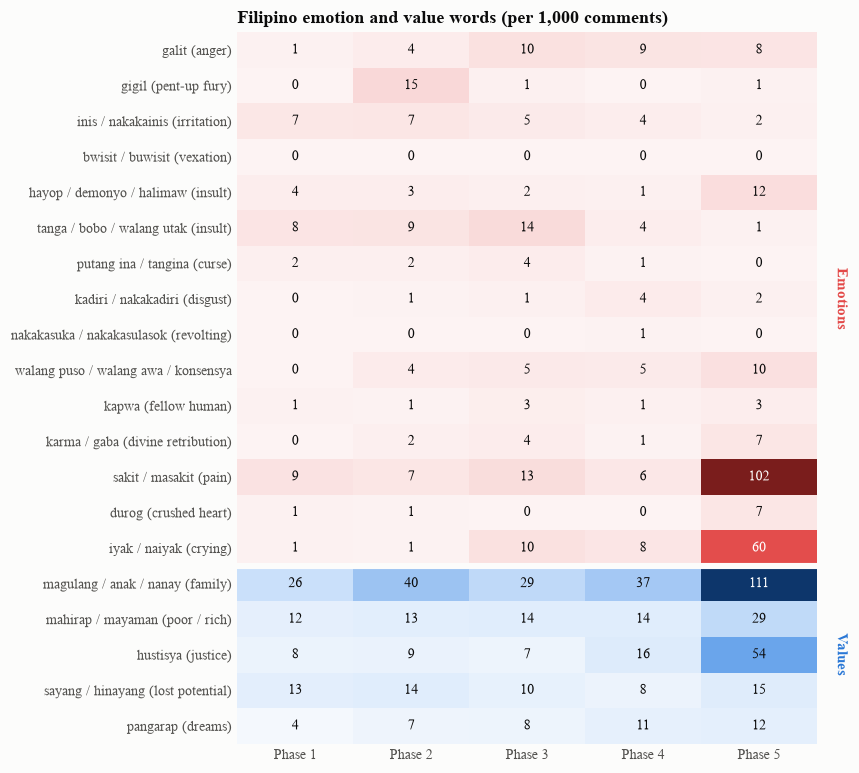

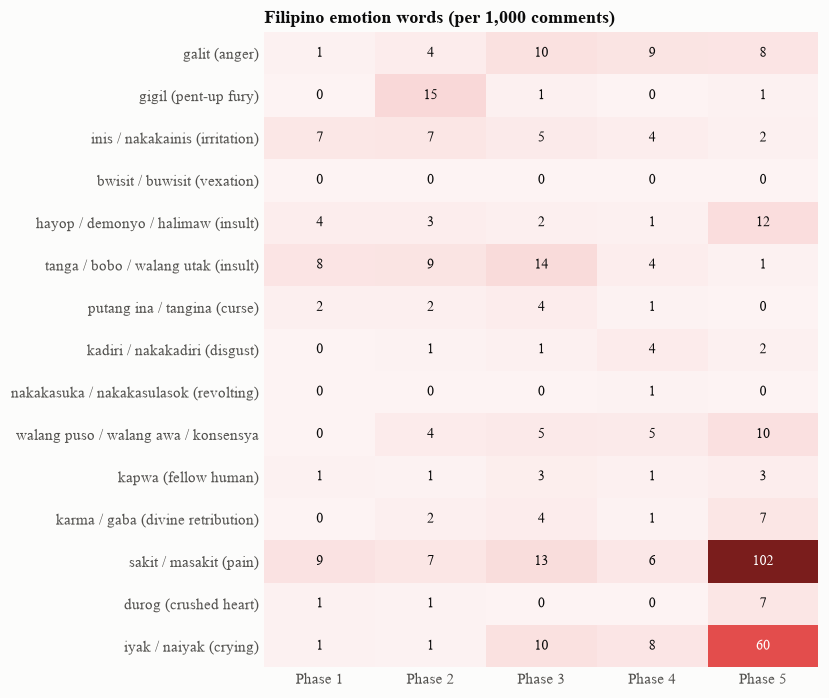

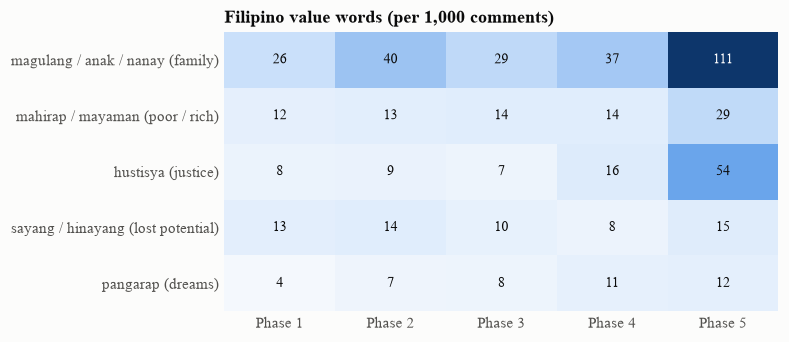

,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
galit (anger),87,0.8,0.1,0.4,1.0,0.9,0.8,0.7,0.036,0.0652,+2.40,0.146,phase-specific (1/5 phases)
gigil (pent-up fury),47,0.4,0.0,1.5,0.1,0.0,0.1,0.1,0.092,8.23e-19,-4.95,1.21e-05,phase-specific (1/5 phases)
inis / nakakainis (irritation),58,0.5,0.7,0.7,0.5,0.4,0.2,-0.5,0.024,0.782,-2.51,0.122,rare (<1% in every phase)
bwisit / buwisit (vexation),1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.010,1,+0.04,1,rare (<1% in every phase)
hayop / demonyo / halimaw (insult),40,0.3,0.4,0.3,0.2,0.1,1.2,0.8,0.052,4.84e-05,+2.81,0.0587,phase-specific (1/5 phases)
tanga / bobo / walang utak (insult),109,0.9,0.8,0.9,1.4,0.4,0.1,-0.7,0.047,0.000496,-2.40,0.146,phase-specific (1/5 phases)
putang ina / tangina (curse),29,0.3,0.2,0.2,0.4,0.1,0.0,-0.2,0.027,0.58,-1.41,0.788,rare (<1% in every phase)
kadiri / nakakadiri (disgust),18,0.2,0.0,0.1,0.1,0.4,0.2,0.2,0.028,0.478,+1.97,0.296,rare (<1% in every phase)
nakakasuka / nakakasulasok (revolting),2,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.017,1,+0.73,1,rare (<1% in every phase)


In [32]:
FIL_LEX = {
    # anger / irritation (Sta. Maria clusters 2-3 and everyday intensifiers)
    "galit (anger)": ("anger", r"galit"),
    "gigil (pent-up fury)": ("anger", r"gigil"),
    "inis / nakakainis (irritation)": ("anger", r"\b(?:naka(?:ka)?|ka|na|nai)?-?inis"),
    "bwisit / buwisit (vexation)": ("anger", r"\bbu?wi?sit"),
    "hayop / demonyo / halimaw (insult)": ("anger", r"\b(?:hayop|demonyo|halimaw)"),
    "tanga / bobo / walang utak (insult)": ("anger", r"\b(?:tanga|bobo|walang\s+utak)"),
    "putang ina / tangina (curse)": ("anger", r"\b(?:puta|putang\s*ina|tang\s*ina|taena|pakshet|pakyu)"),
    # disgust
    "kadiri / nakakadiri (disgust)": ("disgust", r"\b(?:naka(?:ka)?)?kadir[ie]|\bnakakadiri|\byuck|\beww+|disgust"),
    "nakakasuka / nakakasulasok (revolting)": ("disgust", r"nakakasuka|nakakasulasok|sickening|nakakadismaya"),
    # moral emotion and kapwa
    "walang puso / walang awa / konsensya": ("moral", r"walang\s+(?:puso|awa|konsensya|konsensiya)|konsensya|konsensiya"),
    "kapwa (fellow human)": ("moral", r"\bkapwa"),
    "karma / gaba (divine retribution)": ("moral", r"\b(?:karma|gaba)\b"),
    # grief
    "sakit / masakit (pain)": ("grief", r"\b(?:ma|naka(?:ka)?)?sakit"),
    "durog (crushed heart)": ("grief", r"durog"),
    "iyak / naiyak (crying)": ("grief", r"\b(?:na|nag|umi|naka(?:ka)?)?iyak"),
    # values tied to Filipino family and mobility
    "sayang / hinayang (lost potential)": ("value", r"sayang|hinayang"),
    "pangarap (dreams)": ("value", r"pangarap"),
    "magulang / anak / nanay (family)": ("value", r"\b(?:magulang|anak|nanay|tatay|ina\b)"),
    "hustisya (justice)": ("value", r"hustisya"),
    "mahirap / mayaman (poor / rich)": ("class", r"\b(?:mahirap|mayaman|dukha|maralita)"),
}
text = df.text.fillna("").str.lower()
for name, (_, rx) in FIL_LEX.items():
    df[f"L_{name}"] = text.str.contains(rx, regex=True).astype(int)
LCOLS = [f"L_{n}" for n in FIL_LEX]
lex_end = endurance(df, LCOLS, {f"L_{n}": n for n in FIL_LEX})
lex_end.insert(0, "kind", [FIL_LEX[n][0] for n in lex_end.index])
lex_end.to_csv(OUT / "filipino_lexicon_by_phase.csv")
per_1000 = lex_end[PHASE_LABELS] * 10
# Emotion words: anger, disgust, moral emotion and grief, in list order.
# Value words: sayang onward, sorted by total so Family comes first.
EMO_KINDS, VAL_KINDS = ["anger", "disgust", "moral", "grief"], ["value", "class"]
emo_rows = list(lex_end.index[lex_end.kind.isin(EMO_KINDS)])
val_rows = list(lex_end[lex_end.kind.isin(VAL_KINDS)].sort_values("total", ascending=False).index)
EMO_SEQ = LinearSegmentedColormap.from_list("emo", ["#fdf3f3", "#f8cfce", "#f09897", "#e34948", "#b32f2e", "#7a1d1c"])

# One table, emotions in red and values in blue (advisers' note), each with its own colour scale
fig, ax = plt.subplots(figsize=(6.8, 0.36 * (len(emo_rows) + len(val_rows)) + 1.2))
for rows, cmap, off in [(emo_rows, EMO_SEQ, 0), (val_rows, SEQ, len(emo_rows))]:
    vals = per_1000.loc[rows].values
    ax.imshow(vals, cmap=cmap, aspect="auto", extent=(-0.5, 4.5, off + len(rows) - 0.5, off - 0.5))
    for i in range(len(rows)):
        for j in range(len(PHASE_LABELS)):
            ax.text(j, off + i, f"{vals[i, j]:.0f}", ha="center", va="center", fontsize=9,
                    color="#ffffff" if vals[i, j] > 0.55 * vals.max() else "#0b0b0b")
ax.set_ylim(len(emo_rows) + len(val_rows) - 0.5, -0.5)
ax.axhline(len(emo_rows) - 0.5, color="#fcfcfb", linewidth=4)
ax.set_xticks(range(len(PHASE_LABELS)), PHASE_LABELS, fontsize=9)
ax.set_yticks(range(len(emo_rows) + len(val_rows)), emo_rows + val_rows, fontsize=9)
for (label, color), mid in zip([("Emotions", SERIES[7]), ("Values", SERIES[0])],
                               [(len(emo_rows) - 1) / 2, len(emo_rows) + (len(val_rows) - 1) / 2]):
    ax.text(4.65, mid, label, rotation=-90, va="center", ha="left", fontsize=10, fontweight="bold", color=color)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Filipino emotion and value words (per 1,000 comments)")
save(fig, "filipino_lexicon_heatmap")
plt.show()

# The same two groups as separate diagrams
heatmap(per_1000.loc[emo_rows], "Filipino emotion words (per 1,000 comments)", "filipino_lexicon_emotions",
        fmt="{:.0f}", cmap=EMO_SEQ, figsize=(6.5, 0.42 * len(emo_rows) + 1.2))
heatmap(per_1000.loc[val_rows], "Filipino value words (per 1,000 comments)", "filipino_lexicon_values",
        fmt="{:.0f}", figsize=(6.5, 0.42 * len(val_rows) + 1.2))
show(lex_end)

In [33]:
anger = df[df.ANGER == 1]
anger_terms = [c for c in LCOLS if FIL_LEX[c[2:]][0] in ("anger", "disgust")]
print(f"Of {len(anger):,} anger-coded comments, {anger[anger_terms].max(axis=1).mean():.1%} use one of the Filipino "
      "anger/disgust expressions above. Breakdown (% of anger-coded comments):")
display((anger[anger_terms].mean() * 100).round(2).rename(lambda c: c[2:]).sort_values(ascending=False).to_frame("%"))

print("Codebook DISGUST:", int(df.DISGUST.sum()), "comments | CONTEMPT:", int(df.CONTEMPT.sum()),
      "| lexicon disgust words:", int(df[[c for c in LCOLS if FIL_LEX[c[2:]][0] == "disgust"]].max(axis=1).sum()))

Of 5,701 anger-coded comments, 5.7% use one of the Filipino anger/disgust expressions above. Breakdown (% of anger-coded comments):


,%
tanga / bobo / walang utak (insult),1.56
galit (anger),1.33
inis / nakakainis (irritation),0.91
gigil (pent-up fury),0.79
hayop / demonyo / halimaw (insult),0.68
putang ina / tangina (curse),0.46
kadiri / nakakadiri (disgust),0.21
bwisit / buwisit (vexation),0.02
nakakasuka / nakakasulasok (revolting),0.02


Codebook DISGUST: 41 comments | CONTEMPT: 2267 | lexicon disgust words: 19


### F3. Kapwa and the relationship invoked (Sta. Maria)
`KAPWA`: the commenter appeals to the victims or others as fellow human beings or to moral duty
(*"tao rin sila", "anak din 'yan ng iba", "walang puso"*). `HINDI_IBANG_TAO`: the commenter claims to be one of the
group (*"Atenean here"*). `IBANG_TAO`: the target is set apart as an outsider.

In [34]:
rel = pd.crosstab(fe_df.phase, fe_df.RELATIONSHIP_LEVEL.fillna("SCREENED_OUT"), normalize="index") * 100
rel = rel[[c for c in ["KAPWA", "HINDI_IBANG_TAO", "IBANG_TAO"] if c in rel]].set_axis(PHASE_LABELS).round(2)
display(rel)
show(endurance(fe_df, ["KAPWA"], {"KAPWA": "Kapwa appeal"}))

RELATIONSHIP_LEVEL,KAPWA,HINDI_IBANG_TAO,IBANG_TAO
Phase 1,3.88,0.35,0.94
Phase 2,3.12,0.19,0.99
Phase 3,9.73,0.44,2.85
Phase 4,7.67,0.72,1.43
Phase 5,26.17,0.16,1.53


,total,overall_%,Phase 1,Phase 2,Phase 3,Phase 4,Phase 5,change_pp,cramers_v,p_holm,trend_z,p_trend_holm,verdict
item,,,,,,,,,,,,,
Kapwa appeal,1060,9.3,3.9,3.1,9.7,7.7,26.2,22.3,0.224,1.19e-122,+20.14,3.19e-90,"enduring, rising"


### F4. *Hinayang*: the lost potential of the child
Filipino grief over a young death often takes the form of *sayang* / *panghihinayang* (regret over wasted
potential) tied to the child's dreams, schooling and the parents' sacrifice. Here: how the codebook values
`CHILD_POTENTIAL` and `EDUCATION_MOBILITY` overlap with *sayang / hinayang / pangarap* in the comment's own words.

In [35]:
hin = df[["L_sayang / hinayang (lost potential)", "L_pangarap (dreams)"]].max(axis=1)
for v in ["V_CHILD_POTENTIAL", "V_EDUCATION_MOBILITY", "V_PARENT_SACRIFICE", "V_FAMILY"]:
    if v in df:
        print(f"{VAL_NAMES[v]:22s}: {df[v].sum():5d} comments, {df.loc[df[v] == 1].pipe(lambda d: hin[d.index].mean()):.0%} "
              f"use sayang/hinayang/pangarap (vs {hin[df[v] == 0].mean():.0%} of others)")

Child potential       :  1357 comments, 10% use sayang/hinayang/pangarap (vs 1% of others)
Education / mobility  :   488 comments, 6% use sayang/hinayang/pangarap (vs 2% of others)
Parent sacrifice      :   238 comments, 7% use sayang/hinayang/pangarap (vs 2% of others)
Family                :  1403 comments, 5% use sayang/hinayang/pangarap (vs 1% of others)


In [36]:
print("Example comments, Filipino expressions of anger, disgust, kapwa and hinayang:")
ex_cols = ["L_gigil (pent-up fury)", "L_kadiri / nakakadiri (disgust)", "L_walang puso / walang awa / konsensya",
           "L_kapwa (fellow human)", "L_sayang / hinayang (lost potential)", "L_pangarap (dreams)"]
ex = pd.concat([df[df[c] == 1].sample(min(3, int(df[c].sum())), random_state=2).assign(expression=c[2:])
                for c in ex_cols])
ex[["expression", "phase", "text"]]

Example comments, Filipino expressions of anger, disgust, kapwa and hinayang:


,expression,phase,text
1878,gigil (pent-up fury),02-confirmation,kabado bente si ateng ..kakagigil ka mag explain dpat managot ka din e
1660,gigil (pent-up fury),02-confirmation,nakakapang gigil talaga
6899,gigil (pent-up fury),03-spread,"nabanggit ni sam na may kuha silang pic ng warm up sa cctv. while, the legal team of rene mentioned they are having difficulties gathering the footage kc all of a sudden sira daw yung system. sana maki-cooperate na l..."
8217,kadiri / nakakadiri (disgust),03-spread,not convinced and will never. very rehearsed eww.
5533,kadiri / nakakadiri (disgust),03-spread,people are disgusting. they judge based on the picture without context. these kids are struggling and its not there fault. they were traumatized with what happened. its hard for them aswell to lose their teammates. l...
10627,kadiri / nakakadiri (disgust),05-lingering,we should never stop asking for justice. kadiri ang ateneo mamamatay tao. tinuring nilang parang aso pinabayaan nila. nabigla din sila di nila inexpect na buong pilipinas ang impact :grinning_face_with_sweat: karma d...
10655,walang puso / walang awa / konsensya,05-lingering,sayang namali ng napiling school yung akala mong makakatulong sa welfare nya at pamilya biglang nauwi s trahedya. nakakainis makitang nasayang ang talent nya ng mga taong walang puso. matatawag ko clang mamamatay tao...
7352,walang puso / walang awa / konsensya,03-spread,"kung may mga bagay na hindi ninyo masabi ngayon, tandaan ninyo na ang katahimikan ay may bigat din. sana piliin ninyo ang katotohanan habang may pagkakataon pa maaring makalimot ang publiko, pero ang sariling konsens..."
8146,walang puso / walang awa / konsensya,03-spread,at kung isa ka man sa may binitawang mga salita sa mga bata na yan na nasa video. god knows din po ate. nakikita niya lahat even all the bashing you throw that can cause someone a life. laganap ngayon ang suicide at ...
10759,kapwa (fellow human),05-lingering,"ang hirap mawalan ng isang anak. kahit ano pang ngiti sa mukha, sa puso ng isang magulang, sobrang sakit. sana makuha ni rene at divine ang hustisya at katotohanan. ang hirap maging mahirap kase madalas binabalewala ..."


### F5. Values by emotions (cross tab)
For the comments that invoke each value: what share also carries each emotion. Read across a row: e.g. of the
comments that invoke family, how many express *suklam / muhi / poot* (C1). The bottom row is all comments, for
comparison. Family is listed first.

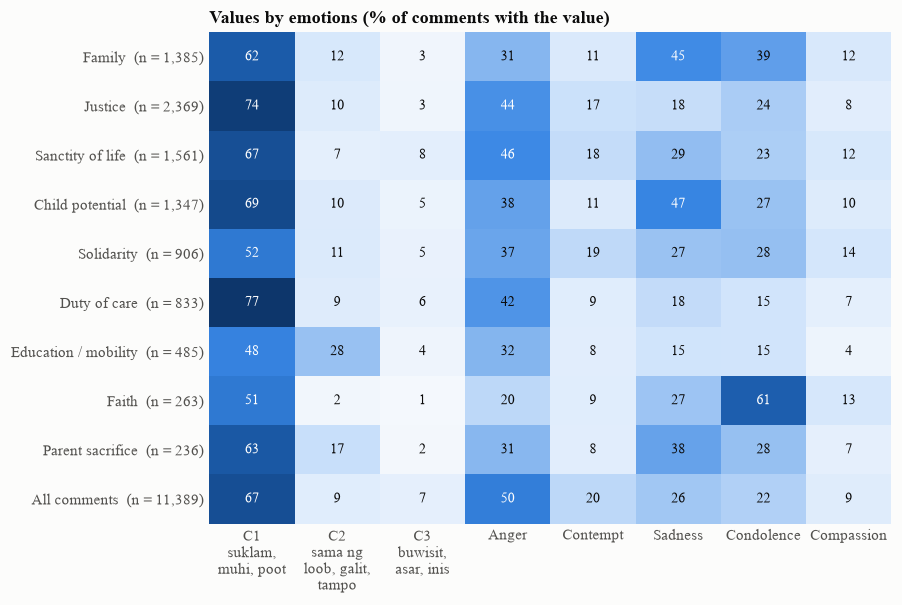

,n,"C1\nsuklam,\nmuhi, poot","C2\nsama ng\nloob, galit,\ntampo","C3\nbuwisit,\nasar, inis",Anger,Contempt,Sadness,Condolence,Compassion
Family,1385,62.1,12.1,2.7,31.5,11.5,45.3,38.8,12.1
Justice,2369,73.9,10.3,3.1,43.6,16.8,17.8,23.8,8.3
Sanctity of life,1561,66.9,7.1,7.6,45.7,18.1,28.8,23.3,12.2
Child potential,1347,69.3,10.4,4.6,38.1,10.5,47.1,27.4,9.9
Solidarity,906,51.5,10.9,5.4,36.8,19.3,27.0,28.3,13.6
Duty of care,833,77.1,9.5,5.8,42.1,8.6,18.5,14.6,7.3
Education / mobility,485,48.0,27.6,3.5,31.8,8.5,14.8,14.6,3.9
Faith,263,51.3,2.3,1.1,19.8,8.7,26.6,60.8,12.5
Parent sacrifice,236,63.1,17.4,1.7,30.9,8.5,37.7,28.0,6.8
All comments,11389,67.1,8.6,6.9,49.7,19.7,25.5,22.3,9.3


In [37]:
ct_df = df[df.fe_ok]
EMO_COLS = {"CLUSTER_C1": "C1\nsuklam,\nmuhi, poot", "CLUSTER_C2": "C2\nsama ng\nloob, galit,\ntampo",
            "CLUSTER_C3": "C3\nbuwisit,\nasar, inis", "ANGER": "Anger", "CONTEMPT": "Contempt",
            "SADNESS": "Sadness", "CONDOLENCE": "Condolence", "COMPASSION_VICTIMS": "Compassion"}
val_order = ["V_FAMILY"] + [v for v in val_end.index.map({n: c for c, n in VAL_NAMES.items()})
                            if v not in ("V_FAMILY", "V_OTHER")]
cross = pd.DataFrame({VAL_NAMES[v]: ct_df.loc[ct_df[v] == 1, list(EMO_COLS)].mean() * 100 for v in val_order}).T
cross.loc["All comments"] = ct_df[list(EMO_COLS)].mean() * 100
cross = cross.rename(columns=EMO_COLS)
cross.insert(0, "n", [int(ct_df[v].sum()) for v in val_order] + [len(ct_df)])
cross.to_csv(OUT / "filipino_values_by_emotions.csv")
heatmap(cross.drop(columns="n").set_axis([f"{i}  (n = {n:,})" for i, n in zip(cross.index, cross.n)]),
        "Values by emotions (% of comments with the value)", "filipino_values_by_emotions", fmt="{:.0f}",
        figsize=(8, 0.42 * len(cross) + 1.6))
cross.round(1)

## Notes for the write-up
* All codes are LLM-assigned (codebook v2.2 / prompt v1.8 and Sta. Maria prompt v1.2); hand-coded agreement is
  reported separately. Sentiment intensity is the model's label probability, a proxy.
* Class themes: BERTopic surfaces the topics and their words; the codebook then measures class framing per comment.
  Section 2a shows which topics carry the class talk.
* Topics per phase and topic persistence live in `05-summary/notebooks/summary.ipynb`. That notebook and
  `youtube-comments-sentiment-change-across-phases.ipynb` still show outputs from the earlier 9-phase split; rerun both
  on the current 5 phases before citing them alongside this notebook. Topic labels are LLM-only until
  `topic-review-sheet.csv` is filled in and applied (`youtube-comments-topic-validation.ipynb`, mode `apply`).
* `02-statistical-analysis.ipynb` still reads the archived v1.4 / 4-bit coding, so its class-talk counts differ from
  section 2b here (v1.8 coding).
* Every table above is saved as CSV and every chart as PNG in `04-statistical-analysis/output/ateneo-drowning/findings/`.